# IndoDiscourse — pipeline

Notebook tunggal untuk alur penelitian: **prepare → EDA → preprocessing → training → evaluasi & visualisasi**.

Default di bawah memakai artefak yang sudah ada (cepat untuk clone/run). Nyalakan flag training bila ingin melatih ulang model.


0. Konfigurasi

In [1]:
# Flag tahap. Default: tampilkan data & visual dari artefak existing (aman setelah clone).
# Set True pada tahap train bila ingin menghasilkan ulang model.
RUN_PREPARE = True
RUN_EDA = True
RUN_CORE_MULTISEED = False   # E0, E1a, E1b, E1c, E3 — True = train ulang
RUN_REMAINING = False        # E2, E4, E5 — True = train ulang
RUN_AGGREGATE = True
RUN_BOOTSTRAP = False
RUN_TEMPERATURE = False
RUN_EFFICIENCY = False
RUN_EXPORT_FIGURES = True
RUN_RENDER_DIAGRAMS = False
SHOW_RESULT_FIGS = True      # figur hasil utama
SHOW_ALL_SEED_FIGS = False   # galeri per-seed (lebih banyak)

# Perangkat
DEVICE_PREFER = "cuda"     # "cuda" atau "cpu"
CUDA_DEVICE_INDEX = 0
CUDA_VISIBLE_DEVICES = "0"
ALLOW_TF32 = True

SEEDS = [42, 43, 44]
CORE_EXPS = ["E0_tfidf_lr", "E1a_textcnn", "E1b_bilstm", "E1c_indobertweet", "E3_soft_mtl"]
REMAINING_EXPS = ["E2", "E4", "E5"]
PIPELINE = "P0"
FORCE = False  # True = paksa train/rebuild meskipun artefak sudah ada


In [2]:
# Lingkungan, GPU, dan helper tampilan.
from __future__ import annotations

import os
import sys
from pathlib import Path

import pandas as pd
import torch
from IPython.display import Image, Markdown, display

ROOT = Path.cwd()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
os.chdir(ROOT)
sys.path.insert(0, str(ROOT / "src"))

if DEVICE_PREFER == "cuda":
    os.environ["CUDA_VISIBLE_DEVICES"] = str(CUDA_VISIBLE_DEVICES)
else:
    os.environ["CUDA_VISIBLE_DEVICES"] = ""

from discourse.utils import get_device


def configure_local_gpu() -> torch.device:
    if DEVICE_PREFER != "cuda":
        print("[device] MODE CPU (DEVICE_PREFER != cuda)")
        return torch.device("cpu")

    if not torch.cuda.is_available():
        print("[peringatan] CUDA tidak tersedia. Fallback ke CPU.")
        print("  Cek: driver NVIDIA, instalasi torch+cuXXX, dan CUDA_VISIBLE_DEVICES.")
        return torch.device("cpu")

    idx = int(CUDA_DEVICE_INDEX)
    if idx < 0 or idx >= torch.cuda.device_count():
        print(f"[peringatan] CUDA_DEVICE_INDEX={idx} tidak valid; memakai 0.")
        idx = 0
    torch.cuda.set_device(idx)
    device = torch.device(f"cuda:{idx}")

    if ALLOW_TF32:
        torch.backends.cuda.matmul.allow_tf32 = True
        torch.backends.cudnn.allow_tf32 = True
    torch.backends.cudnn.benchmark = True

    props = torch.cuda.get_device_properties(idx)
    total_gb = props.total_memory / (1024**3)
    print("[device] MODE GPU")
    print("  name:", torch.cuda.get_device_name(idx))
    print("  index:", idx, "| visible_devices:", os.environ.get("CUDA_VISIBLE_DEVICES"))
    print("  capability:", f"{props.major}.{props.minor}", "| vram_total_gb:", round(total_gb, 2))
    print("  torch:", torch.__version__, "| cuda_runtime:", torch.version.cuda)
    return device


def show_png(path: Path, max_width: int = 900) -> None:
    if path.exists():
        display(Markdown(f"**{path.relative_to(ROOT)}**"))
        display(Image(filename=str(path), width=max_width))
    else:
        print("[missing]", path)


device = configure_local_gpu()
_ = get_device("cuda" if device.type == "cuda" else "cpu")
print("ROOT:", ROOT)
print("SEEDS:", SEEDS, "| FORCE:", FORCE, "| DEVICE_PREFER:", DEVICE_PREFER)
print("Active torch device:", device)


[device] MODE GPU lokal
  name: NVIDIA GeForce RTX 5060 Laptop GPU
  index: 0 | visible_devices: 0
  capability: 12.0 | vram_total_gb: 7.96
  torch: 2.12.0.dev20260407+cu128 | cuda_runtime: 12.8
ROOT: e:\Work-Project\deep-learning-nlp
SEEDS: [42, 43, 44] | FORCE: False | DEVICE_PREFER: cuda
Active torch device: cuda:0


Step 1 — Prepare

Menjalankan `discourse.prepare.prepare_all`. **Kode lengkap** `prepare.py`, `schema.py`, `targets.py`, `split.py`, `preprocessing.py`, `audit.py` dicantumkan (dikomentari) di blok *Kode inti penelitian* pada Step 3–5.


In [ ]:
from discourse.prepare import prepare_all

processed = ROOT / "data" / "processed" / "all_splits.parquet"

# -----------------------------------------------------------------------------
# KODE INTI PREPARE (terlihat). Sumber penuh dicantumkan di Step 3-5 (dikomentari):
#   prepare.py, schema.py, targets.py, split.py, preprocessing.py, audit.py
# Equivalen:
#   result = prepare_all(config_path="configs/data.yaml", pipeline=PIPELINE)
# -----------------------------------------------------------------------------

if RUN_PREPARE or not processed.exists():
    result = prepare_all(config_path="configs/data.yaml", pipeline=PIPELINE)
    print("n_valid:", result["n_valid"])
else:
    print("Skip prepare; memakai", processed)

all_df = pd.read_parquet(processed)
print(all_df["split"].value_counts().to_dict())
display(all_df.head(3))


Step 2 — EDA

Menjalankan `discourse.eda.run_eda` (atau menampilkan figur existing). **Kode lengkap** `eda.py` dicantumkan (dikomentari) di blok *Kode inti penelitian* pada Step 3–5.


In [ ]:
from discourse.eda import run_eda

# -----------------------------------------------------------------------------
# KODE INTI EDA (terlihat). Sumber penuh eda.py dicantumkan di Step 3-5 (dikomentari).
# Equivalen:
#   run_eda(all_df, fig_dir=ROOT/"artifacts"/"figures", table_dir=ROOT/"artifacts"/"tables")
# -----------------------------------------------------------------------------

if RUN_EDA:
    run_eda(all_df, fig_dir=ROOT / "artifacts" / "figures", table_dir=ROOT / "artifacts" / "tables")
    print("EDA selesai")
else:
    print("Skip EDA — menampilkan figur existing")

eda_figs = [
    ROOT / "artifacts" / "figures" / "laporan" / "09_ukuran_split.png",
    ROOT / "artifacts" / "figures" / "laporan" / "02_label_mayoritas.png",
    ROOT / "artifacts" / "figures" / "laporan" / "05_distribusi_soft_toksisitas.png",
    ROOT / "artifacts" / "figures" / "laporan" / "05_distribusi_soft_polarisasi.png",
]
for path in eda_figs:
    show_png(path, max_width=720)


Step 3–5 — Inti penelitian: **semua kode inti dicantumkan (dikomentari)** + setup + demo model + train opsional

Di bawah: (1) tabel setup YAML aktif, (2) **seluruh kode inti & configs sebagai komentar penuh** agar terlihat, (3) demo dimensi/parameter & loss, (4) pemanggilan train multi-seed (flag).


### Peta eksperimen inti (core)

| ID | Model | Target | Peran ilmiah |
|---|---|---|---|
| E0 | TF-IDF + Logistic Regression | hard | Baseline linear n-gram |
| E1a | TextCNN | hard | Pola lokal (kernel 3/5/7) |
| E1b | BiLSTM + Attention | hard | Konteks sekuensial dua arah |
| E1c | IndoBERTweet dual-head | hard | MTL hard-label (backbone utama) |
| E3 | IndoBERTweet dual-head | **soft** | MTL disagreement-preserving (arsitektur = E1c) |

Semua model dual-task mengeluarkan **2 logit** (toksisitas, polarisasi) + sigmoid/BCE masked. E3 vs E1c membandingkan hard vs soft pada arsitektur yang sama.


In [ ]:
# Tabel setup dari configs/*.yaml (sumber kebenaran hiperparameter)
from discourse.utils import load_yaml

CFG_FILES = {
    "E0_tfidf_lr": None,  # baseline sklearn di run_core (bukan YAML neural)
    "E1a_textcnn": "configs/textcnn.yaml",
    "E1b_bilstm": "configs/bilstm.yaml",
    "E1c_indobertweet": "configs/indobertweet.yaml",
    "E3_soft_mtl": "configs/multitask_soft.yaml",
    "E2_stl_tox": "configs/e2_stl_tox.yaml",
    "E2_stl_pol": "configs/e2_stl_pol.yaml",
    "E4_consistency": "configs/e4_consistency.yaml",
    "E5_soft_mtl": "configs/e5_soft_mtl.yaml",
}

rows = []
for exp_id, rel in CFG_FILES.items():
    if rel is None:
        rows.append({
            "experiment_id": exp_id,
            "model": "tfidf_lr",
            "dim/hidden": "-",
            "max_length": "-",
            "batch_eff": "-",
            "lr": "sklearn default + balanced",
            "epochs": "-",
            "weight_decay": "-",
            "target_mode": "hard",
            "consistency_weight": 0.0,
            "task_mode": "per-task LR",
            "selection": "val macro-F1 (threshold scan)",
        })
        continue
    cfg = load_yaml(ROOT / rel)
    tr = cfg["training"]
    md_ = cfg["model"]
    batch_eff = int(tr["micro_batch_size"]) * int(tr.get("gradient_accumulation", 1))
    dim = md_.get("dim") or md_.get("hidden") or md_.get("checkpoint", "")
    rows.append({
        "experiment_id": cfg.get("experiment_id", exp_id),
        "model": md_.get("name"),
        "dim/hidden": dim,
        "max_length": tr.get("max_length"),
        "batch_eff": batch_eff,
        "lr": tr.get("learning_rate"),
        "epochs": tr.get("epochs"),
        "weight_decay": tr.get("weight_decay"),
        "target_mode": tr.get("target_mode"),
        "consistency_weight": tr.get("consistency_weight", 0.0),
        "task_mode": tr.get("task_mode", "multitask"),
        "selection": cfg.get("selection", {}).get("metric"),
    })

setup_df = pd.DataFrame(rows)
display(Markdown("### Setup eksperimen (dari YAML)"))
display(setup_df)
print("SEEDS protokol:", SEEDS)


### Kode inti penelitian (dicantumkan & dikomentari)

Semua modul inti yang dipakai pipeline ditampilkan di bawah sebagai **komentar penuh** agar terlihat saat scroll/video, tanpa mengeksekusi ulang dari cell ini.

Urutan: configs YAML → models/losses/targets/train → data/prepare/EDA → evaluate/predict → run_core/run_remaining.

Cell aktif (instansiasi, demo loss, train opsional) tetap ada setelah blok komentar.


#### Konfigurasi YAML eksperimen (dikomentari)


`configs/data.yaml`


In [ ]:
# =============================================================================
# configs/data.yaml
# Dicantumkan agar terlihat di notebook / video. TIDAK dieksekusi dari cell ini.
# Sumber kebenaran tetap file di repo; cell aktif di bawah memanggil modul lewat import.
# =============================================================================
#
# dataset:
#   repo: Exqrch/IndoDiscourse
#   revision: null
#   local_path: IndoDiscourse/indotoxic2024_annotated_data_v2_final.jsonl
# columns:
#   text_id: text_id
#   text: text
#   toxicity: toxicity
#   polarization: polarized
#   annotators: annotators_id
# split:
#   seed: 42
#   train: 0.70
#   validation: 0.15
#   test: 0.15
# preprocessing:
#   pipeline: P0
#   slang_dictionary: null
# device: cuda
# paths:
#   figures: artifacts/figures
#   metrics: artifacts/metrics
#   tables: artifacts/tables
#   predictions: artifacts/predictions
#   checkpoints: artifacts/checkpoints
#   audits: artifacts/audits
#   splits: data/splits
#
# (akhir cuplikan)


`configs/textcnn.yaml`


In [ ]:
# =============================================================================
# configs/textcnn.yaml
# Dicantumkan agar terlihat di notebook / video. TIDAK dieksekusi dari cell ini.
# Sumber kebenaran tetap file di repo; cell aktif di bawah memanggil modul lewat import.
# =============================================================================
#
# experiment_id: E1a_textcnn
# seed: 42
# model:
#   name: textcnn
#   dim: 128
#   channels: 128
# training:
#   max_length: 128
#   micro_batch_size: 64
#   gradient_accumulation: 1
#   learning_rate: 0.001
#   weight_decay: 0.0001
#   epochs: 5
#   gradient_clip: 1.0
#   precision: fp32
#   target_mode: hard
#   consistency_weight: 0.0
# selection:
#   metric: validation_mean_macro_f1
#
# (akhir cuplikan)


`configs/bilstm.yaml`


In [ ]:
# =============================================================================
# configs/bilstm.yaml
# Dicantumkan agar terlihat di notebook / video. TIDAK dieksekusi dari cell ini.
# Sumber kebenaran tetap file di repo; cell aktif di bawah memanggil modul lewat import.
# =============================================================================
#
# experiment_id: E1b_bilstm
# seed: 42
# model:
#   name: bilstm
#   dim: 128
#   hidden: 128
# training:
#   max_length: 128
#   micro_batch_size: 64
#   gradient_accumulation: 1
#   learning_rate: 0.001
#   weight_decay: 0.0001
#   epochs: 5
#   gradient_clip: 1.0
#   precision: fp32
#   target_mode: hard
#   consistency_weight: 0.0
# selection:
#   metric: validation_mean_macro_f1
#
# (akhir cuplikan)


`configs/indobertweet.yaml`


In [ ]:
# =============================================================================
# configs/indobertweet.yaml
# Dicantumkan agar terlihat di notebook / video. TIDAK dieksekusi dari cell ini.
# Sumber kebenaran tetap file di repo; cell aktif di bawah memanggil modul lewat import.
# =============================================================================
#
# experiment_id: E1c_indobertweet
# seed: 42
# model:
#   name: transformer
#   checkpoint: indolem/indobertweet-base-uncased
# training:
#   max_length: 128
#   micro_batch_size: 8
#   gradient_accumulation: 2
#   learning_rate: 0.00002
#   weight_decay: 0.01
#   epochs: 3
#   gradient_clip: 1.0
#   precision: fp32
#   target_mode: hard
#   consistency_weight: 0.0
# selection:
#   metric: validation_mean_macro_f1
#
# (akhir cuplikan)


`configs/multitask_soft.yaml`


In [ ]:
# =============================================================================
# configs/multitask_soft.yaml
# Dicantumkan agar terlihat di notebook / video. TIDAK dieksekusi dari cell ini.
# Sumber kebenaran tetap file di repo; cell aktif di bawah memanggil modul lewat import.
# =============================================================================
#
# experiment_id: E3_soft_mtl
# seed: 42
# model:
#   name: transformer
#   checkpoint: indolem/indobertweet-base-uncased
# training:
#   max_length: 128
#   micro_batch_size: 8
#   gradient_accumulation: 2
#   learning_rate: 0.00002
#   weight_decay: 0.01
#   epochs: 3
#   gradient_clip: 1.0
#   precision: fp32
#   target_mode: soft
#   consistency_weight: 0.0
# selection:
#   metric: validation_mean_macro_f1
#
# (akhir cuplikan)


`configs/e2_stl_tox.yaml`


In [ ]:
# =============================================================================
# configs/e2_stl_tox.yaml
# Dicantumkan agar terlihat di notebook / video. TIDAK dieksekusi dari cell ini.
# Sumber kebenaran tetap file di repo; cell aktif di bawah memanggil modul lewat import.
# =============================================================================
#
# experiment_id: E2_stl_tox
# seed: 42
# model:
#   name: transformer
#   checkpoint: indolem/indobertweet-base-uncased
# training:
#   max_length: 128
#   micro_batch_size: 8
#   gradient_accumulation: 2
#   learning_rate: 0.00002
#   weight_decay: 0.01
#   epochs: 3
#   gradient_clip: 1.0
#   precision: fp32
#   target_mode: hard
#   task_mode: tox
#   consistency_weight: 0.0
# selection:
#   metric: validation_mean_macro_f1
#
# (akhir cuplikan)


`configs/e2_stl_pol.yaml`


In [ ]:
# =============================================================================
# configs/e2_stl_pol.yaml
# Dicantumkan agar terlihat di notebook / video. TIDAK dieksekusi dari cell ini.
# Sumber kebenaran tetap file di repo; cell aktif di bawah memanggil modul lewat import.
# =============================================================================
#
# experiment_id: E2_stl_pol
# seed: 42
# model:
#   name: transformer
#   checkpoint: indolem/indobertweet-base-uncased
# training:
#   max_length: 128
#   micro_batch_size: 8
#   gradient_accumulation: 2
#   learning_rate: 0.00002
#   weight_decay: 0.01
#   epochs: 3
#   gradient_clip: 1.0
#   precision: fp32
#   target_mode: hard
#   task_mode: pol
#   consistency_weight: 0.0
# selection:
#   metric: validation_mean_macro_f1
#
# (akhir cuplikan)


`configs/e4_consistency.yaml`


In [ ]:
# =============================================================================
# configs/e4_consistency.yaml
# Dicantumkan agar terlihat di notebook / video. TIDAK dieksekusi dari cell ini.
# Sumber kebenaran tetap file di repo; cell aktif di bawah memanggil modul lewat import.
# =============================================================================
#
# experiment_id: E4_consistency
# seed: 42
# model:
#   name: transformer
#   checkpoint: indolem/indobertweet-base-uncased
# training:
#   max_length: 128
#   micro_batch_size: 8
#   gradient_accumulation: 2
#   learning_rate: 0.00002
#   weight_decay: 0.01
#   epochs: 3
#   gradient_clip: 1.0
#   precision: fp32
#   target_mode: soft
#   task_mode: multitask
#   consistency_weight: 0.5
# selection:
#   metric: validation_mean_macro_f1
#
# (akhir cuplikan)


`configs/e5_soft_mtl.yaml`


In [ ]:
# =============================================================================
# configs/e5_soft_mtl.yaml
# Dicantumkan agar terlihat di notebook / video. TIDAK dieksekusi dari cell ini.
# Sumber kebenaran tetap file di repo; cell aktif di bawah memanggil modul lewat import.
# =============================================================================
#
# experiment_id: E5_soft_mtl
# seed: 42
# model:
#   name: transformer
#   checkpoint: indolem/indobertweet-base-uncased
# training:
#   max_length: 128
#   micro_batch_size: 8
#   gradient_accumulation: 2
#   learning_rate: 0.00002
#   weight_decay: 0.01
#   epochs: 3
#   gradient_clip: 1.0
#   precision: fp32
#   target_mode: soft
#   task_mode: multitask
#   consistency_weight: 0.0
# selection:
#   metric: validation_mean_macro_f1
#
# (akhir cuplikan)


#### Modul `src/discourse/` inti (dikomentari)


`src/discourse/models.py` — Arsitektur TextCNN, BiLSTM-Attention, TransformerMultiTask


In [ ]:
# =============================================================================
# src/discourse/models.py — Arsitektur TextCNN, BiLSTM-Attention, TransformerMultiTask
# Dicantumkan agar terlihat di notebook / video. TIDAK dieksekusi dari cell ini.
# Sumber kebenaran tetap file di repo; cell aktif di bawah memanggil modul lewat import.
# =============================================================================
#
# from __future__ import annotations
#
# import torch
# from torch import nn
# from transformers import AutoModel
#
#
# class TextCNN(nn.Module):
#     def __init__(self, vocab_size, dim=128, channels=128, pad_id=0):
#         super().__init__()
#         self.embedding = nn.Embedding(vocab_size, dim, padding_idx=pad_id)
#         self.convs = nn.ModuleList(
#             [nn.Conv1d(dim, channels, k, padding=k // 2) for k in (3, 5, 7)]
#         )
#         self.dropout = nn.Dropout(0.2)
#         self.head = nn.Linear(channels * 3, 2)
#
#     def forward(self, input_ids, attention_mask):
#         x = self.embedding(input_ids).transpose(1, 2)
#         valid = attention_mask.bool().unsqueeze(1)
#         pooled = []
#         for conv in self.convs:
#             h = torch.relu(conv(x))
#             h = h.masked_fill(~valid, torch.finfo(h.dtype).min)
#             pooled.append(h.max(dim=-1).values)
#         return self.head(self.dropout(torch.cat(pooled, dim=-1)))
#
#
# class BiLSTMAttention(nn.Module):
#     def __init__(self, vocab_size, dim=128, hidden=128, pad_id=0):
#         super().__init__()
#         self.embedding = nn.Embedding(vocab_size, dim, padding_idx=pad_id)
#         self.lstm = nn.LSTM(dim, hidden, batch_first=True, bidirectional=True)
#         self.attention = nn.Linear(hidden * 2, 1)
#         self.head = nn.Sequential(nn.Dropout(0.2), nn.Linear(hidden * 2, 2))
#
#     def forward(self, input_ids, attention_mask):
#         lengths = attention_mask.sum(dim=1).cpu().clamp(min=1)
#         x = self.embedding(input_ids)
#         packed = nn.utils.rnn.pack_padded_sequence(
#             x, lengths, batch_first=True, enforce_sorted=False
#         )
#         packed_h, _ = self.lstm(packed)
#         h, _ = nn.utils.rnn.pad_packed_sequence(
#             packed_h, batch_first=True, total_length=input_ids.size(1)
#         )
#         scores = self.attention(h).squeeze(-1)
#         scores = scores.masked_fill(~attention_mask.bool(), torch.finfo(scores.dtype).min)
#         weights = torch.softmax(scores, dim=1)
#         z = (h * weights.unsqueeze(-1)).sum(dim=1)
#         return self.head(z)
#
#
# class TransformerMultiTask(nn.Module):
#     def __init__(self, checkpoint, dropout=0.1):
#         super().__init__()
#         self.encoder = AutoModel.from_pretrained(checkpoint)
#         self.dropout = nn.Dropout(dropout)
#         self.head = nn.Linear(self.encoder.config.hidden_size, 2)
#
#     def forward(self, input_ids, attention_mask):
#         out = self.encoder(input_ids=input_ids, attention_mask=attention_mask)
#         return self.head(self.dropout(out.last_hidden_state[:, 0]))
#
# (akhir cuplikan)


`src/discourse/losses.py` — Masked BCE multitask + consistency MSE


In [ ]:
# =============================================================================
# src/discourse/losses.py — Masked BCE multitask + consistency MSE
# Dicantumkan agar terlihat di notebook / video. TIDAK dieksekusi dari cell ini.
# Sumber kebenaran tetap file di repo; cell aktif di bawah memanggil modul lewat import.
# =============================================================================
#
# from __future__ import annotations
#
# import torch.nn.functional as F
#
#
# def masked_task_bce(logits, targets, masks):
#     elementwise = F.binary_cross_entropy_with_logits(logits, targets, reduction="none")
#     counts = masks.sum(dim=0)
#     per_task = (elementwise * masks).sum(dim=0) / counts.clamp_min(1)
#     active = counts > 0
#     if not active.any():
#         raise ValueError("Batch contains no valid supervision")
#     return per_task[active].mean()
#
#
# def prediction_consistency(logits_a, logits_b):
#     return F.mse_loss(logits_a.sigmoid(), logits_b.sigmoid())
#
#
# def total_loss(logits, targets, masks, augmented_logits=None, consistency_weight=0.0):
#     loss = masked_task_bce(logits, targets, masks)
#     if augmented_logits is not None and consistency_weight > 0:
#         loss = loss + consistency_weight * prediction_consistency(logits, augmented_logits)
#     return loss
#
# (akhir cuplikan)


`src/discourse/targets.py` — Hard/soft label dari suara anotator


In [ ]:
# =============================================================================
# src/discourse/targets.py — Hard/soft label dari suara anotator
# Dicantumkan agar terlihat di notebook / video. TIDAK dieksekusi dari cell ini.
# Sumber kebenaran tetap file di repo; cell aktif di bawah memanggil modul lewat import.
# =============================================================================
#
# from __future__ import annotations
#
# import ast
# import json
# import math
#
# import pandas as pd
#
#
# def parse_list(value):
#     if isinstance(value, list):
#         return value
#     if value is None or (isinstance(value, float) and math.isnan(value)):
#         return []
#     if isinstance(value, str):
#         value = value.strip()
#         if not value:
#             return []
#         try:
#             parsed = json.loads(value)
#         except json.JSONDecodeError:
#             parsed = ast.literal_eval(value)
#         if not isinstance(parsed, list):
#             raise ValueError("Expected list")
#         return parsed
#     raise TypeError(f"Unsupported annotation type: {type(value)}")
#
#
# def _to_binary(v):
#     if isinstance(v, bool):
#         return int(v)
#     if isinstance(v, (int, float)) and not isinstance(v, bool):
#         if v in (0, 1, 0.0, 1.0):
#             return int(v)
#     if isinstance(v, str):
#         s = v.strip()
#         if s in {"0", "1"}:
#             return int(s)
#     raise ValueError(f"Votes must contain only 0 or 1, got {v!r}")
#
#
# def summarize_votes(values):
#     raw = parse_list(values)
#     votes = [_to_binary(v) for v in raw]
#     n = len(votes)
#     if n == 0:
#         return dict(n=0, q=None, hard=None, mask=False, entropy=None, multi=False)
#     q = sum(votes) / n
#     entropy = 0.0
#     if 0 < q < 1:
#         entropy = -q * math.log2(q) - (1 - q) * math.log2(1 - q)
#     return dict(
#         n=n,
#         q=q,
#         hard=None if q == 0.5 else int(q > 0.5),
#         mask=True,
#         entropy=entropy,
#         multi=n >= 2,
#     )
#
#
# def add_targets(df: pd.DataFrame) -> pd.DataFrame:
#     out = df.copy()
#     for source, suffix in [("votes_tox", "tox"), ("votes_pol", "pol")]:
#         stats = out[source].map(summarize_votes)
#         stats = pd.DataFrame(stats.tolist(), index=out.index)
#         stats.columns = [f"{c}_{suffix}" for c in stats.columns]
#         out = pd.concat([out, stats], axis=1)
#     return out
#
# (akhir cuplikan)


`src/discourse/train.py` — build_model, train_epoch, run_training


In [ ]:
# =============================================================================
# src/discourse/train.py — build_model, train_epoch, run_training
# Dicantumkan agar terlihat di notebook / video. TIDAK dieksekusi dari cell ini.
# Sumber kebenaran tetap file di repo; cell aktif di bawah memanggil modul lewat import.
# =============================================================================
#
# from __future__ import annotations
#
# from pathlib import Path
# from typing import Any
#
# import pandas as pd
# import torch
# from torch.utils.data import DataLoader
# from tqdm.auto import tqdm
#
# from discourse.datasets import DiscourseDataset, collate_batch
# from discourse.evaluate import evaluate_loader, select_thresholds
# from discourse.losses import total_loss
# from discourse.models import BiLSTMAttention, TextCNN, TransformerMultiTask
# from discourse.tokenization import build_word_vocab, load_hf_tokenizer
# from discourse.utils import ensure_dir, get_device, save_json, set_seed
#
#
# def build_model(cfg: dict, vocab_size: int | None = None):
#     name = cfg["model"]["name"]
#     if name == "textcnn":
#         return TextCNN(
#             vocab_size,
#             dim=cfg["model"].get("dim", 128),
#             channels=cfg["model"].get("channels", 128),
#         )
#     if name == "bilstm":
#         return BiLSTMAttention(
#             vocab_size,
#             dim=cfg["model"].get("dim", 128),
#             hidden=cfg["model"].get("hidden", 128),
#         )
#     if name == "transformer":
#         return TransformerMultiTask(cfg["model"]["checkpoint"])
#     raise ValueError(f"Unknown model: {name}")
#
#
# def train_epoch(model, loader, optimizer, device, accumulation=1, consistency_weight=0.0):
#     model.train()
#     optimizer.zero_grad(set_to_none=True)
#     running_loss = 0.0
#     n_batches = len(loader)
#     tensor_keys = {
#         "input_ids",
#         "attention_mask",
#         "targets",
#         "target_masks",
#         "aug_input_ids",
#         "aug_attention_mask",
#     }
#     for step, batch in enumerate(loader):
#         tensor_batch = {k: v.to(device) for k, v in batch.items() if k in tensor_keys}
#         logits = model(tensor_batch["input_ids"], tensor_batch["attention_mask"])
#         aug_logits = None
#         if consistency_weight > 0 and "aug_input_ids" in tensor_batch:
#             aug_logits = model(tensor_batch["aug_input_ids"], tensor_batch["aug_attention_mask"])
#         loss = total_loss(
#             logits,
#             tensor_batch["targets"],
#             tensor_batch["target_masks"],
#             augmented_logits=aug_logits,
#             consistency_weight=consistency_weight,
#         )
#         window_start = (step // accumulation) * accumulation
#         window_size = min(accumulation, n_batches - window_start)
#         (loss / window_size).backward()
#         if (step + 1) % accumulation == 0 or step + 1 == n_batches:
#             torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
#             optimizer.step()
#             optimizer.zero_grad(set_to_none=True)
#         running_loss += loss.item()
#     return running_loss / max(n_batches, 1)
#
#
# def run_training(
#     cfg: dict,
#     train_df: pd.DataFrame,
#     val_df: pd.DataFrame,
#     out_dir: str | Path,
#     device_prefer: str = "cuda",
# ) -> dict[str, Any]:
#     set_seed(cfg.get("seed", 42))
#     device = get_device(device_prefer)
#     out_dir = ensure_dir(out_dir)
#     max_length = cfg["training"]["max_length"]
#     target_mode = cfg["training"].get("target_mode", "hard")
#     batch_size = cfg["training"]["micro_batch_size"]
#     accum = cfg["training"].get("gradient_accumulation", 1)
#
#     tokenizer = None
#     vocab = None
#     vocab_size = None
#     if cfg["model"]["name"] == "transformer":
#         tokenizer = load_hf_tokenizer(cfg["model"]["checkpoint"])
#     else:
#         vocab = build_word_vocab(train_df["text_proc"].tolist())
#         vocab_size = len(vocab)
#         save_json(vocab, out_dir / "vocab.json")
#
#     task_mode = cfg["training"].get("task_mode", "multitask")
#     consistency_weight = float(cfg["training"].get("consistency_weight", 0.0))
#     augment_fn = None
#     if consistency_weight > 0:
#         from discourse.perturbation import make_augment_fn
#
#         augment_fn = make_augment_fn(seed=int(cfg.get("seed", 42)))
#
#     train_ds = DiscourseDataset(
#         train_df,
#         tokenizer=tokenizer,
#         vocab=vocab,
#         max_length=max_length,
#         target_mode=target_mode,
#         task_mode=task_mode,
#         augment_fn=augment_fn,
#     )
#     val_ds = DiscourseDataset(
#         val_df,
#         tokenizer=tokenizer,
#         vocab=vocab,
#         max_length=max_length,
#         target_mode=target_mode,
#         task_mode=task_mode,
#         augment_fn=None,
#     )
#     train_loader = DataLoader(
#         train_ds, batch_size=batch_size, shuffle=True, collate_fn=collate_batch
#     )
#     val_loader = DataLoader(
#         val_ds, batch_size=batch_size, shuffle=False, collate_fn=collate_batch
#     )
#
#     model = build_model(cfg, vocab_size=vocab_size).to(device)
#     optimizer = torch.optim.AdamW(
#         model.parameters(),
#         lr=cfg["training"]["learning_rate"],
#         weight_decay=cfg["training"].get("weight_decay", 0.0),
#     )
#
#     history = []
#     best_score = -1.0
#     best_path = out_dir / "best.pt"
#     thresholds = {"tox": 0.5, "pol": 0.5}
#
#     for epoch in range(1, cfg["training"]["epochs"] + 1):
#         tr_loss = train_epoch(
#             model,
#             train_loader,
#             optimizer,
#             device,
#             accumulation=accum,
#             consistency_weight=cfg["training"].get("consistency_weight", 0.0),
#         )
#         val_pred = evaluate_loader(model, val_loader, device)
#         thresholds = select_thresholds(val_pred)
#         metrics = summarize_preds(val_pred, thresholds, task_mode=task_mode)
#         row = {"epoch": epoch, "train_loss": tr_loss, **metrics}
#         history.append(row)
#         score = metrics.get("mean_macro_f1", 0.0)
#         if score > best_score:
#             best_score = score
#             torch.save(
#                 {
#                     "model_state": model.state_dict(),
#                     "cfg": cfg,
#                     "thresholds": thresholds,
#                     "vocab": vocab,
#                     "epoch": epoch,
#                     "metrics": metrics,
#                 },
#                 best_path,
#             )
#         print(
#             f"[{cfg.get('experiment_id')}] epoch={epoch} loss={tr_loss:.4f} "
#             f"mean_macro_f1={score:.4f} device={device}"
#         )
#
#     hist_df = pd.DataFrame(history)
#     hist_df.to_csv(out_dir / "history.csv", index=False)
#     save_json(
#         {
#             "experiment_id": cfg.get("experiment_id"),
#             "device": str(device),
#             "best_score": best_score,
#             "thresholds": thresholds,
#             "best_checkpoint": str(best_path),
#         },
#         out_dir / "run_meta.json",
#     )
#     return {
#         "history": hist_df,
#         "best_path": best_path,
#         "thresholds": thresholds,
#         "device": str(device),
#         "best_score": best_score,
#     }
#
#
# def summarize_preds(
#     pred_df: pd.DataFrame,
#     thresholds: dict[str, float],
#     task_mode: str = "multitask",
# ) -> dict[str, float]:
#     from discourse.evaluate import classification_metrics
#
#     if task_mode == "tox":
#         tasks = [("tox", "tox")]
#     elif task_mode == "pol":
#         tasks = [("pol", "pol")]
#     else:
#         tasks = [("tox", "tox"), ("pol", "pol")]
#
#     scores = []
#     out = {}
#     for task, thr_key in tasks:
#         m = classification_metrics(pred_df, task=task, threshold=thresholds[thr_key])
#         out[f"{task}_macro_f1"] = m["macro_f1"]
#         out[f"{task}_pos_f1"] = m["pos_f1"]
#         out[f"{task}_ap"] = m["average_precision"]
#         if m["macro_f1"] == m["macro_f1"]:  # not nan
#             scores.append(m["macro_f1"])
#     out["mean_macro_f1"] = float(sum(scores) / len(scores)) if scores else 0.0
#     return out
#
# (akhir cuplikan)


`src/discourse/datasets.py` — Dataset + collate batch (targets/masks/augment)


In [ ]:
# =============================================================================
# src/discourse/datasets.py — Dataset + collate batch (targets/masks/augment)
# Dicantumkan agar terlihat di notebook / video. TIDAK dieksekusi dari cell ini.
# Sumber kebenaran tetap file di repo; cell aktif di bawah memanggil modul lewat import.
# =============================================================================
#
# from __future__ import annotations
#
# from typing import Any
#
# import numpy as np
# import pandas as pd
# import torch
# from torch.utils.data import Dataset
#
# from discourse.tokenization import encode_words
#
#
# class DiscourseDataset(Dataset):
#     def __init__(
#         self,
#         df: pd.DataFrame,
#         text_col: str = "text_proc",
#         target_mode: str = "hard",
#         tokenizer=None,
#         vocab: dict[str, int] | None = None,
#         max_length: int = 128,
#         task_mode: str = "multitask",  # multitask | tox | pol
#         augment_fn=None,
#     ):
#         self.df = df.reset_index(drop=True)
#         self.text_col = text_col
#         self.target_mode = target_mode
#         self.tokenizer = tokenizer
#         self.vocab = vocab
#         self.max_length = max_length
#         self.task_mode = task_mode
#         self.augment_fn = augment_fn
#
#     def __len__(self):
#         return len(self.df)
#
#     def _targets_masks(self, row) -> tuple[np.ndarray, np.ndarray]:
#         if self.target_mode == "hard":
#             t_tox = row["hard_tox"]
#             t_pol = row["hard_pol"]
#             # hard mode: only non-tie / available majority
#             m_tox = bool(row["mask_tox"]) and pd.notna(t_tox)
#             m_pol = bool(row["mask_pol"]) and pd.notna(t_pol)
#             y_tox = float(t_tox) if m_tox else 0.0
#             y_pol = float(t_pol) if m_pol else 0.0
#         else:
#             m_tox = bool(row["mask_tox"]) and pd.notna(row["q_tox"])
#             m_pol = bool(row["mask_pol"]) and pd.notna(row["q_pol"])
#             y_tox = float(row["q_tox"]) if m_tox else 0.0
#             y_pol = float(row["q_pol"]) if m_pol else 0.0
#
#         if self.task_mode == "tox":
#             m_pol = False
#         elif self.task_mode == "pol":
#             m_tox = False
#
#         targets = np.array([y_tox, y_pol], dtype=np.float32)
#         masks = np.array([float(m_tox), float(m_pol)], dtype=np.float32)
#         return targets, masks
#
#     def _encode(self, text: str) -> tuple[torch.Tensor, torch.Tensor]:
#         if self.tokenizer is not None:
#             enc = self.tokenizer(
#                 text,
#                 truncation=True,
#                 max_length=self.max_length,
#                 padding="max_length",
#                 return_tensors="pt",
#             )
#             return enc["input_ids"].squeeze(0), enc["attention_mask"].squeeze(0)
#         ids, attn = encode_words(text, self.vocab, self.max_length)
#         return torch.tensor(ids, dtype=torch.long), torch.tensor(attn, dtype=torch.long)
#
#     def __getitem__(self, idx: int) -> dict[str, Any]:
#         row = self.df.iloc[idx]
#         text = str(row[self.text_col])
#         input_ids, attention_mask = self._encode(text)
#
#         targets, masks = self._targets_masks(row)
#         item = {
#             "input_ids": input_ids,
#             "attention_mask": attention_mask,
#             "targets": torch.tensor(targets),
#             "target_masks": torch.tensor(masks),
#             "text_id": str(row["text_id"]),
#             "n_tox": int(row.get("n_tox", 0) or 0),
#             "n_pol": int(row.get("n_pol", 0) or 0),
#             "q_tox": row.get("q_tox"),
#             "q_pol": row.get("q_pol"),
#             "hard_tox": row.get("hard_tox"),
#             "hard_pol": row.get("hard_pol"),
#         }
#         if self.augment_fn is not None:
#             aug_text = self.augment_fn(text)
#             aug_ids, aug_attn = self._encode(aug_text)
#             item["aug_input_ids"] = aug_ids
#             item["aug_attention_mask"] = aug_attn
#         return item
#
#
# def collate_batch(batch: list[dict[str, Any]]) -> dict[str, Any]:
#     meta_keys = ["text_id", "n_tox", "n_pol", "q_tox", "q_pol", "hard_tox", "hard_pol"]
#     out: dict[str, Any] = {}
#     tensor_keys = ["input_ids", "attention_mask", "targets", "target_masks"]
#     if "aug_input_ids" in batch[0]:
#         tensor_keys.extend(["aug_input_ids", "aug_attention_mask"])
#     for k in tensor_keys:
#         out[k] = torch.stack([b[k] for b in batch], dim=0)
#     for k in meta_keys:
#         out[k] = [b[k] for b in batch]
#     return out
#
# (akhir cuplikan)


`src/discourse/tokenization.py` — Word vocab + HF tokenizer


In [ ]:
# =============================================================================
# src/discourse/tokenization.py — Word vocab + HF tokenizer
# Dicantumkan agar terlihat di notebook / video. TIDAK dieksekusi dari cell ini.
# Sumber kebenaran tetap file di repo; cell aktif di bawah memanggil modul lewat import.
# =============================================================================
#
# from __future__ import annotations
#
# from collections import Counter
# from typing import Iterable
#
# from transformers import AutoTokenizer
#
#
# SPECIALS = ["<pad>", "<unk>"]
#
#
# def build_word_vocab(texts: Iterable[str], min_freq: int = 2) -> dict[str, int]:
#     counter = Counter()
#     for t in texts:
#         counter.update(str(t).lower().split())
#     vocab = {tok: i for i, tok in enumerate(SPECIALS)}
#     for tok, freq in counter.items():
#         if freq >= min_freq and tok not in vocab:
#             vocab[tok] = len(vocab)
#     return vocab
#
#
# def encode_words(text: str, vocab: dict[str, int], max_length: int = 128):
#     unk = vocab["<unk>"]
#     pad = vocab["<pad>"]
#     ids = [vocab.get(tok, unk) for tok in str(text).lower().split()][:max_length]
#     if not ids:
#         ids = [unk]
#     attn = [1] * len(ids)
#     while len(ids) < max_length:
#         ids.append(pad)
#         attn.append(0)
#     return ids, attn
#
#
# def load_hf_tokenizer(checkpoint: str = "indolem/indobertweet-base-uncased"):
#     return AutoTokenizer.from_pretrained(checkpoint)
#
# (akhir cuplikan)


`src/discourse/prepare.py` — Prepare end-to-end: audit, target, split, preprocess


In [ ]:
# =============================================================================
# src/discourse/prepare.py — Prepare end-to-end: audit, target, split, preprocess
# Dicantumkan agar terlihat di notebook / video. TIDAK dieksekusi dari cell ini.
# Sumber kebenaran tetap file di repo; cell aktif di bawah memanggil modul lewat import.
# =============================================================================
#
# from __future__ import annotations
#
# from pathlib import Path
#
# import pandas as pd
#
# from discourse.audit import audit_annotations, filter_valid
# from discourse.download import prepare_local_dataset
# from discourse.duplicates import assign_group_ids, duplicate_report
# from discourse.preprocessing import apply_preprocessing
# from discourse.schema import load_raw_jsonl, schema_report, validate_and_map
# from discourse.split import make_splits, save_splits
# from discourse.targets import add_targets
# from discourse.utils import ensure_dir, load_yaml, project_root, save_json
#
#
# def prepare_all(config_path: str | Path = "configs/data.yaml", pipeline: str = "P0") -> dict:
#     root = project_root()
#     cfg = load_yaml(root / config_path)
#     raw_path = prepare_local_dataset(cfg["dataset"]["local_path"])
#
#     df_raw = load_raw_jsonl(raw_path)
#     df = validate_and_map(df_raw, cfg["columns"])
#     report = schema_report(df_raw, df)
#     save_json(report, root / "artifacts" / "audits" / "schema_report.json")
#
#     # stable internal id
#     df.insert(0, "text_id", [f"t{i:06d}" for i in range(len(df))])
#     df = add_targets(df)
#     audit = audit_annotations(df)
#     save_json(audit, root / "artifacts" / "audits" / "annotation_audit.json")
#
#     valid, dropped = filter_valid(df)
#     dropped.to_csv(root / "artifacts" / "audits" / "dropped_rows.csv", index=False)
#     pd.DataFrame(
#         [
#             {
#                 "n_raw": len(df_raw),
#                 "n_mapped": len(df),
#                 "n_valid": len(valid),
#                 "n_dropped": len(dropped),
#                 "n_tox_valid": int(valid["mask_tox"].sum()),
#                 "n_pol_valid": int(valid["mask_pol"].sum()),
#                 "n_both_valid": int((valid["mask_tox"] & valid["mask_pol"]).sum()),
#                 "n_multi_tox": int(valid["multi_tox"].sum()),
#                 "n_multi_pol": int(valid["multi_pol"].sum()),
#             }
#         ]
#     ).to_csv(root / "artifacts" / "tables" / "sample_counts.csv", index=False)
#
#     valid = assign_group_ids(valid)
#     dups = duplicate_report(valid)
#     dups.to_csv(root / "artifacts" / "audits" / "exact_duplicates.csv", index=False)
#
#     parts = make_splits(valid, seed=cfg["split"]["seed"])
#     # preprocessing after split decision; fit dictionaries on train only later
#     for name in parts:
#         parts[name] = apply_preprocessing(parts[name], pipeline=pipeline)
#
#     split_meta = save_splits(parts, root / cfg["paths"]["splits"])
#     # also save combined processed parquet/csv
#     processed_dir = ensure_dir(root / "data" / "processed")
#     combined = pd.concat(parts.values(), ignore_index=True)
#     combined.to_parquet(processed_dir / "all_splits.parquet", index=False)
#     combined.to_csv(processed_dir / "all_splits.csv", index=False)
#
#     # split audit table
#     audit_rows = []
#     for name, part in parts.items():
#         audit_rows.append(
#             {
#                 "split": name,
#                 "n": len(part),
#                 "n_groups": part["group_id"].nunique(),
#                 "tox_pos": int((part["hard_tox"] == 1).sum()),
#                 "tox_neg": int((part["hard_tox"] == 0).sum()),
#                 "tox_tie_or_missing": int(part["hard_tox"].isna().sum()),
#                 "pol_pos": int((part["hard_pol"] == 1).sum()),
#                 "pol_neg": int((part["hard_pol"] == 0).sum()),
#                 "pol_tie_or_missing": int(part["hard_pol"].isna().sum()),
#             }
#         )
#     pd.DataFrame(audit_rows).to_csv(root / "artifacts" / "tables" / "split_label_audit.csv", index=False)
#
#     return {
#         "raw_path": str(raw_path),
#         "n_valid": len(valid),
#         "split_meta": split_meta,
#         "parts": parts,
#         "audit": audit,
#         "schema": report,
#     }
#
# (akhir cuplikan)


`src/discourse/eda.py` — EDA tabel & figur


In [ ]:
# =============================================================================
# src/discourse/eda.py — EDA tabel & figur
# Dicantumkan agar terlihat di notebook / video. TIDAK dieksekusi dari cell ini.
# Sumber kebenaran tetap file di repo; cell aktif di bawah memanggil modul lewat import.
# =============================================================================
#
# from __future__ import annotations
#
# from pathlib import Path
#
# import matplotlib.pyplot as plt
# import pandas as pd
# import seaborn as sns
#
# from discourse.utils import ensure_dir
#
#
# def _save(fig, path: Path):
#     ensure_dir(path.parent)
#     fig.savefig(path, dpi=150, bbox_inches="tight")
#     plt.close(fig)
#
#
# def run_eda(df: pd.DataFrame, fig_dir: str | Path, table_dir: str | Path) -> dict:
#     fig_dir = ensure_dir(fig_dir)
#     table_dir = ensure_dir(table_dir)
#     sns.set_theme(style="whitegrid")
#     summary = {}
#
#     # G01 availability
#     avail = pd.DataFrame(
#         {
#             "subset": ["tox_only", "pol_only", "both", "either"],
#             "count": [
#                 int(((df.mask_tox) & (~df.mask_pol)).sum()),
#                 int(((~df.mask_tox) & (df.mask_pol)).sum()),
#                 int(((df.mask_tox) & (df.mask_pol)).sum()),
#                 int(((df.mask_tox) | (df.mask_pol)).sum()),
#             ],
#         }
#     )
#     avail.to_csv(table_dir / "G01_target_availability.csv", index=False)
#     fig, ax = plt.subplots(figsize=(6, 4))
#     sns.barplot(data=avail, x="subset", y="count", ax=ax, color="#3b82f6")
#     ax.set_title("G01 Target availability")
#     _save(fig, fig_dir / "G01_target_availability.png")
#     summary["G01"] = avail.to_dict(orient="records")
#
#     # G02 majority labels
#     rows = []
#     for task, hard_col in [("toxicity", "hard_tox"), ("polarization", "hard_pol")]:
#         sub = df[df[hard_col].notna()]
#         vc = sub[hard_col].value_counts(dropna=False).rename({0: "neg", 1: "pos"})
#         for lab, cnt in vc.items():
#             rows.append({"task": task, "label": lab, "count": int(cnt)})
#     maj = pd.DataFrame(rows)
#     maj.to_csv(table_dir / "G02_majority_labels.csv", index=False)
#     fig, ax = plt.subplots(figsize=(6, 4))
#     sns.barplot(data=maj, x="task", y="count", hue="label", ax=ax)
#     ax.set_title("G02 Majority label distribution (non-tie)")
#     _save(fig, fig_dir / "G02_majority_labels.png")
#
#     # G03 joint labels
#     both = df[df.hard_tox.notna() & df.hard_pol.notna()].copy()
#     ct = pd.crosstab(both["hard_tox"], both["hard_pol"])
#     ct.to_csv(table_dir / "G03_joint_labels.csv")
#     fig, ax = plt.subplots(figsize=(5, 4))
#     sns.heatmap(ct, annot=True, fmt="d", cmap="Blues", ax=ax)
#     ax.set_xlabel("polarization hard")
#     ax.set_ylabel("toxicity hard")
#     ax.set_title("G03 Joint majority labels")
#     _save(fig, fig_dir / "G03_joint_labels.png")
#
#     # G04 annotator counts
#     n_rows = []
#     for task, n_col, mask_col in [
#         ("toxicity", "n_tox", "mask_tox"),
#         ("polarization", "n_pol", "mask_pol"),
#     ]:
#         vc = df.loc[df[mask_col], n_col].value_counts().sort_index()
#         for n_ann, cnt in vc.items():
#             n_rows.append({"task": task, "n_annotators": int(n_ann), "count": int(cnt)})
#     nann = pd.DataFrame(n_rows)
#     nann.to_csv(table_dir / "G04_annotator_counts.csv", index=False)
#     fig, ax = plt.subplots(figsize=(7, 4))
#     sns.barplot(data=nann, x="n_annotators", y="count", hue="task", ax=ax)
#     ax.set_title("G04 Annotator count distribution")
#     _save(fig, fig_dir / "G04_annotator_counts.png")
#
#     # G05 soft label distribution
#     soft_rows = []
#     for task, q_col, mask_col in [
#         ("toxicity", "q_tox", "mask_tox"),
#         ("polarization", "q_pol", "mask_pol"),
#     ]:
#         qs = df.loc[df[mask_col], q_col].dropna()
#         soft_rows.append(
#             {
#                 "task": task,
#                 "mean_q": float(qs.mean()),
#                 "std_q": float(qs.std()),
#                 "n": int(len(qs)),
#             }
#         )
#         fig, ax = plt.subplots(figsize=(6, 4))
#         ax.hist(qs, bins=11, color="#6366f1", edgecolor="white")
#         ax.set_title(f"G05 Soft label distribution — {task}")
#         ax.set_xlabel("q (positive vote proportion)")
#         _save(fig, fig_dir / f"G05_soft_{task}.png")
#     pd.DataFrame(soft_rows).to_csv(table_dir / "G05_soft_summary.csv", index=False)
#
#     # G06 entropy vs n annotators
#     ent_rows = []
#     for task, ent_col, n_col, mask_col in [
#         ("toxicity", "entropy_tox", "n_tox", "mask_tox"),
#         ("polarization", "entropy_pol", "n_pol", "mask_pol"),
#     ]:
#         sub = df.loc[df[mask_col], [ent_col, n_col]].dropna()
#         g = sub.groupby(n_col)[ent_col].mean().reset_index()
#         g.columns = ["n_annotators", "mean_entropy"]
#         g["task"] = task
#         ent_rows.append(g)
#         fig, ax = plt.subplots(figsize=(6, 4))
#         sns.boxplot(data=sub, x=n_col, y=ent_col, ax=ax, color="#14b8a6")
#         ax.set_title(f"G06 Entropy by annotator count — {task}")
#         _save(fig, fig_dir / f"G06_entropy_{task}.png")
#     pd.concat(ent_rows, ignore_index=True).to_csv(table_dir / "G06_entropy_by_n.csv", index=False)
#
#     # G07 text length (chars / words)
#     df = df.copy()
#     df["char_len"] = df["text_raw"].astype(str).str.len()
#     df["word_len"] = df["text_raw"].astype(str).str.split().str.len()
#     len_sum = df[["char_len", "word_len"]].describe().T
#     len_sum.to_csv(table_dir / "G07_text_length.csv")
#     fig, axes = plt.subplots(1, 2, figsize=(10, 4))
#     axes[0].hist(df["char_len"].clip(upper=df["char_len"].quantile(0.99)), bins=40, color="#f59e0b")
#     axes[0].set_title("G07 Char length")
#     axes[1].hist(df["word_len"].clip(upper=df["word_len"].quantile(0.99)), bins=40, color="#ef4444")
#     axes[1].set_title("G07 Word length")
#     _save(fig, fig_dir / "G07_text_length.png")
#
#     # G09 URL/mention/emoji rough flags
#     import re
#
#     text = df["text_raw"].fillna("").astype(str)
#     texts = text.tolist()
#     emoji_re = re.compile("[\U0001F300-\U0001FAFF]")
#     flags = pd.DataFrame(
#         {
#             "feature": ["has_url", "has_mention", "has_emoji_like"],
#             "count": [
#                 int(text.str.contains(r"https?://|www\.", regex=True, na=False).sum()),
#                 int(text.str.contains(r"(?<!\w)@\w+", regex=True, na=False).sum()),
#                 int(sum(bool(emoji_re.search(str(t))) for t in texts)),
#             ],
#         }
#     )
#     flags.to_csv(table_dir / "G09_surface_features.csv", index=False)
#     fig, ax = plt.subplots(figsize=(6, 4))
#     sns.barplot(data=flags, x="feature", y="count", ax=ax, color="#8b5cf6")
#     ax.set_title("G09 URL / mention / emoji-like")
#     _save(fig, fig_dir / "G09_surface_features.png")
#
#     # G10 split distributions if present
#     if "split" in df.columns:
#         split_rows = []
#         for split_name, g in df.groupby("split"):
#             split_rows.append(
#                 {
#                     "split": split_name,
#                     "n": len(g),
#                     "tox_pos_rate": float(g.loc[g.hard_tox.notna(), "hard_tox"].mean())
#                     if g.hard_tox.notna().any()
#                     else None,
#                     "pol_pos_rate": float(g.loc[g.hard_pol.notna(), "hard_pol"].mean())
#                     if g.hard_pol.notna().any()
#                     else None,
#                     "mean_char_len": float(g["char_len"].mean()),
#                 }
#             )
#         split_df = pd.DataFrame(split_rows)
#         split_df.to_csv(table_dir / "G10_split_audit.csv", index=False)
#         fig, ax = plt.subplots(figsize=(6, 4))
#         sns.barplot(data=split_df, x="split", y="n", ax=ax, color="#0ea5e9")
#         ax.set_title("G10 Split sizes")
#         _save(fig, fig_dir / "G10_split_sizes.png")
#
#     summary["n_rows"] = int(len(df))
#     return summary
#
# (akhir cuplikan)


`src/discourse/preprocessing.py` — Pipeline P0/P1/P2


In [ ]:
# =============================================================================
# src/discourse/preprocessing.py — Pipeline P0/P1/P2
# Dicantumkan agar terlihat di notebook / video. TIDAK dieksekusi dari cell ini.
# Sumber kebenaran tetap file di repo; cell aktif di bawah memanggil modul lewat import.
# =============================================================================
#
# from __future__ import annotations
#
# import re
# import unicodedata
#
# URL = re.compile(r"https?://\S+|www\.\S+")
# MENTION = re.compile(r"(?<!\w)@\w+")
#
#
# def preprocess(text, pipeline="P0", slang=None):
#     text = unicodedata.normalize("NFC", str(text))
#     text = re.sub(r"\s+", " ", text).strip()
#     if pipeline in {"P1", "P2"}:
#         text = URL.sub("URLTOKEN", text)
#         text = MENTION.sub("USERTOKEN", text)
#     if pipeline == "P2":
#         if slang is None:
#             raise ValueError("P2 requires an audited slang dictionary")
#         tokens = re.split(r"(\W+)", text)
#         text = "".join(slang.get(t.lower(), t) for t in tokens)
#     return text
#
#
# def apply_preprocessing(df, pipeline="P0", slang=None, text_col="text_raw"):
#     out = df.copy()
#     out["text_proc"] = out[text_col].map(lambda t: preprocess(t, pipeline=pipeline, slang=slang))
#     out["pipeline"] = pipeline
#     return out
#
# (akhir cuplikan)


`src/discourse/split.py` — Split 70/15/15 group-aware


In [ ]:
# =============================================================================
# src/discourse/split.py — Split 70/15/15 group-aware
# Dicantumkan agar terlihat di notebook / video. TIDAK dieksekusi dari cell ini.
# Sumber kebenaran tetap file di repo; cell aktif di bawah memanggil modul lewat import.
# =============================================================================
#
# from __future__ import annotations
#
# from pathlib import Path
#
# import pandas as pd
# from sklearn.model_selection import GroupShuffleSplit
#
# from discourse.utils import ensure_dir, save_json, sha256_file
#
#
# def make_splits(df: pd.DataFrame, seed: int = 42) -> dict[str, pd.DataFrame]:
#     outer = GroupShuffleSplit(n_splits=1, test_size=0.15, random_state=seed)
#     trainval_idx, test_idx = next(outer.split(df, groups=df["group_id"]))
#     trainval = df.iloc[trainval_idx]
#     inner = GroupShuffleSplit(n_splits=1, test_size=0.15 / 0.85, random_state=seed)
#     train_idx, val_idx = next(inner.split(trainval, groups=trainval["group_id"]))
#     parts = {
#         "train": trainval.iloc[train_idx].copy(),
#         "validation": trainval.iloc[val_idx].copy(),
#         "test": df.iloc[test_idx].copy(),
#     }
#     for name, part in parts.items():
#         part["split"] = name
#     groups = {k: set(v["group_id"]) for k, v in parts.items()}
#     assert not groups["train"] & groups["validation"]
#     assert not groups["train"] & groups["test"]
#     assert not groups["validation"] & groups["test"]
#     return parts
#
#
# def save_splits(parts: dict[str, pd.DataFrame], out_dir: str | Path) -> dict:
#     out_dir = ensure_dir(out_dir)
#     paths = {}
#     for name, part in parts.items():
#         path = out_dir / f"{name}.parquet"
#         part.to_parquet(path, index=False)
#         paths[name] = str(path)
#     combined = pd.concat(parts.values(), ignore_index=True)
#     ids_path = out_dir / "split_ids.csv"
#     combined[["text_id", "group_id", "split"]].to_csv(ids_path, index=False)
#     meta = {
#         "n_train": len(parts["train"]),
#         "n_validation": len(parts["validation"]),
#         "n_test": len(parts["test"]),
#         "paths": paths,
#         "split_ids_csv": str(ids_path),
#         "split_ids_sha256": sha256_file(ids_path),
#     }
#     save_json(meta, Path(out_dir) / "split_meta.json")
#     return meta
#
# (akhir cuplikan)


`src/discourse/schema.py` — Validasi/mapping skema IndoDiscourse


In [ ]:
# =============================================================================
# src/discourse/schema.py — Validasi/mapping skema IndoDiscourse
# Dicantumkan agar terlihat di notebook / video. TIDAK dieksekusi dari cell ini.
# Sumber kebenaran tetap file di repo; cell aktif di bawah memanggil modul lewat import.
# =============================================================================
#
# from __future__ import annotations
#
# from pathlib import Path
# from typing import Any
#
# import pandas as pd
#
# REQUIRED_COLUMNS = {
#     "text_id": "text_id",
#     "text": "text",
#     "toxicity": "toxicity",
#     "polarization": "polarized",  # actual HF column name
#     "annotators": "annotators_id",
# }
#
#
# def load_raw_jsonl(path: str | Path) -> pd.DataFrame:
#     path = Path(path)
#     if not path.exists():
#         raise FileNotFoundError(path)
#     df = pd.read_json(path, lines=True)
#     return df
#
#
# def validate_and_map(
#     df: pd.DataFrame,
#     columns: dict[str, str] | None = None,
# ) -> pd.DataFrame:
#     columns = columns or REQUIRED_COLUMNS
#     missing = [src for src in columns.values() if src not in df.columns]
#     if missing:
#         raise ValueError(
#             f"Schema mismatch. Missing columns: {missing}. "
#             f"Available: {list(df.columns)}"
#         )
#
#     out = pd.DataFrame()
#     out["source_ids"] = df[columns["text_id"]].astype(str)
#     out["text_raw"] = df[columns["text"]].astype(str)
#     out["votes_tox"] = df[columns["toxicity"]]
#     out["votes_pol"] = df[columns["polarization"]]
#     out["annotators_id"] = df[columns["annotators"]]
#
#     # keep useful optional metadata if present
#     for opt in ("topic", "initial_paragraph"):
#         if opt in df.columns:
#             out[opt] = df[opt]
#
#     return out
#
#
# def schema_report(df_raw: pd.DataFrame, df_mapped: pd.DataFrame) -> dict[str, Any]:
#     return {
#         "n_raw_rows": int(len(df_raw)),
#         "n_mapped_rows": int(len(df_mapped)),
#         "raw_columns": list(df_raw.columns),
#         "mapped_columns": list(df_mapped.columns),
#         "empty_text": int((df_mapped["text_raw"].str.strip() == "").sum()),
#         "null_text": int(df_mapped["text_raw"].isna().sum()),
#     }
#
# (akhir cuplikan)


`src/discourse/audit.py` — Audit anotasi


In [ ]:
# =============================================================================
# src/discourse/audit.py — Audit anotasi
# Dicantumkan agar terlihat di notebook / video. TIDAK dieksekusi dari cell ini.
# Sumber kebenaran tetap file di repo; cell aktif di bawah memanggil modul lewat import.
# =============================================================================
#
# from __future__ import annotations
#
# from typing import Any
#
# import pandas as pd
#
# from discourse.targets import parse_list, _to_binary
#
#
# def audit_annotations(df: pd.DataFrame) -> dict[str, Any]:
#     issues = []
#     n = len(df)
#     empty_text = (df["text_raw"].astype(str).str.strip() == "").sum()
#
#     bad_tox = 0
#     bad_pol = 0
#     len_mismatch = 0
#     for i, row in df.iterrows():
#         try:
#             tox = [_to_binary(v) for v in parse_list(row["votes_tox"])]
#         except Exception as e:
#             bad_tox += 1
#             issues.append({"text_id": row.get("text_id"), "issue": f"toxicity: {e}"})
#             tox = None
#         try:
#             pol = [_to_binary(v) for v in parse_list(row["votes_pol"])]
#         except Exception as e:
#             bad_pol += 1
#             issues.append({"text_id": row.get("text_id"), "issue": f"polarization: {e}"})
#             pol = None
#         try:
#             anns = parse_list(row.get("annotators_id", []))
#         except Exception:
#             anns = []
#         if tox is not None and pol is not None:
#             if not (len(tox) == len(pol) == len(anns) or (len(anns) == 0)):
#                 # allow missing annotators list length only if empty; else flag
#                 if len(anns) > 0 and (len(tox) != len(anns) or len(pol) != len(anns)):
#                     len_mismatch += 1
#                     issues.append(
#                         {
#                             "text_id": row.get("text_id"),
#                             "issue": f"length mismatch tox={len(tox)} pol={len(pol)} ann={len(anns)}",
#                         }
#                     )
#
#     return {
#         "n_rows": int(n),
#         "empty_text": int(empty_text),
#         "bad_toxicity": int(bad_tox),
#         "bad_polarization": int(bad_pol),
#         "annotator_length_mismatch": int(len_mismatch),
#         "n_issue_rows": len(issues),
#         "issues_sample": issues[:50],
#     }
#
#
# def filter_valid(df: pd.DataFrame) -> tuple[pd.DataFrame, pd.DataFrame]:
#     """Drop empty text; keep rows with at least one valid task annotation."""
#     out = df.copy()
#     out = out[out["text_raw"].astype(str).str.strip() != ""].copy()
#     keep = (out["mask_tox"] == True) | (out["mask_pol"] == True)  # noqa: E712
#     valid = out[keep].copy()
#     dropped = out[~keep].copy()
#     return valid, dropped
#
# (akhir cuplikan)


`src/discourse/duplicates.py` — Group near-duplicate


In [ ]:
# =============================================================================
# src/discourse/duplicates.py — Group near-duplicate
# Dicantumkan agar terlihat di notebook / video. TIDAK dieksekusi dari cell ini.
# Sumber kebenaran tetap file di repo; cell aktif di bawah memanggil modul lewat import.
# =============================================================================
#
# from __future__ import annotations
#
# import hashlib
#
# import pandas as pd
#
#
# def exact_text_group_id(text: str) -> str:
#     norm = " ".join(str(text).split()).lower()
#     return hashlib.md5(norm.encode("utf-8")).hexdigest()
#
#
# def assign_group_ids(df: pd.DataFrame, text_col: str = "text_raw") -> pd.DataFrame:
#     out = df.copy()
#     out["group_id"] = out[text_col].map(exact_text_group_id)
#     return out
#
#
# def duplicate_report(df: pd.DataFrame) -> pd.DataFrame:
#     g = (
#         df.groupby("group_id")
#         .agg(n_rows=("text_id", "count"), sample_text=("text_raw", "first"))
#         .reset_index()
#     )
#     dups = g[g["n_rows"] > 1].sort_values("n_rows", ascending=False)
#     return dups
#
# (akhir cuplikan)


`src/discourse/evaluate.py` — Metrik klasifikasi, soft, figur CM/PR


In [ ]:
# =============================================================================
# src/discourse/evaluate.py — Metrik klasifikasi, soft, figur CM/PR
# Dicantumkan agar terlihat di notebook / video. TIDAK dieksekusi dari cell ini.
# Sumber kebenaran tetap file di repo; cell aktif di bawah memanggil modul lewat import.
# =============================================================================
#
# from __future__ import annotations
#
# from pathlib import Path
#
# import matplotlib.pyplot as plt
# import numpy as np
# import pandas as pd
# import seaborn as sns
# import torch
# from sklearn.metrics import (
#     average_precision_score,
#     confusion_matrix,
#     f1_score,
#     precision_recall_curve,
#     precision_score,
#     recall_score,
#     roc_auc_score,
# )
# from tqdm.auto import tqdm
#
# from discourse.calibration import reliability_diagram
# from discourse.utils import ensure_dir
#
#
# @torch.no_grad()
# def evaluate_loader(model, loader, device) -> pd.DataFrame:
#     model.eval()
#     rows = []
#     for batch in tqdm(loader, leave=False):
#         input_ids = batch["input_ids"].to(device)
#         attention_mask = batch["attention_mask"].to(device)
#         logits = model(input_ids, attention_mask)
#         probs = torch.sigmoid(logits).cpu().numpy()
#         for i in range(len(batch["text_id"])):
#             rows.append(
#                 {
#                     "text_id": batch["text_id"][i],
#                     "prob_tox": float(probs[i, 0]),
#                     "prob_pol": float(probs[i, 1]),
#                     "n_tox": batch["n_tox"][i],
#                     "n_pol": batch["n_pol"][i],
#                     "q_tox": batch["q_tox"][i],
#                     "q_pol": batch["q_pol"][i],
#                     "hard_tox": batch["hard_tox"][i],
#                     "hard_pol": batch["hard_pol"][i],
#                     "mask_tox": float(batch["target_masks"][i, 0]),
#                     "mask_pol": float(batch["target_masks"][i, 1]),
#                 }
#             )
#     return pd.DataFrame(rows)
#
#
# def classification_metrics(pred_df: pd.DataFrame, task: str, threshold: float = 0.5) -> dict:
#     hard_col = f"hard_{task}"
#     prob_col = f"prob_{task}"
#     sub = pred_df[pred_df[hard_col].notna()].copy()
#     if len(sub) == 0:
#         return {
#             "n": 0,
#             "macro_f1": float("nan"),
#             "pos_f1": float("nan"),
#             "precision": float("nan"),
#             "recall": float("nan"),
#             "average_precision": float("nan"),
#             "roc_auc": float("nan"),
#         }
#     y_true = sub[hard_col].astype(int).to_numpy()
#     y_prob = sub[prob_col].to_numpy()
#     y_pred = (y_prob >= threshold).astype(int)
#     out = {
#         "n": int(len(sub)),
#         "macro_f1": float(f1_score(y_true, y_pred, average="macro", zero_division=0)),
#         "pos_f1": float(f1_score(y_true, y_pred, pos_label=1, zero_division=0)),
#         "precision": float(precision_score(y_true, y_pred, pos_label=1, zero_division=0)),
#         "recall": float(recall_score(y_true, y_pred, pos_label=1, zero_division=0)),
#         "average_precision": float(average_precision_score(y_true, y_prob))
#         if len(np.unique(y_true)) > 1
#         else float("nan"),
#         "roc_auc": float(roc_auc_score(y_true, y_prob))
#         if len(np.unique(y_true)) > 1
#         else float("nan"),
#         "threshold": threshold,
#     }
#     return out
#
#
# def select_thresholds(pred_df: pd.DataFrame) -> dict[str, float]:
#     thresholds = {}
#     for task in ("tox", "pol"):
#         hard_col = f"hard_{task}"
#         prob_col = f"prob_{task}"
#         sub = pred_df[pred_df[hard_col].notna()]
#         if len(sub) == 0 or sub[hard_col].nunique() < 2:
#             thresholds[task] = 0.5
#             continue
#         y_true = sub[hard_col].astype(int).to_numpy()
#         y_prob = sub[prob_col].to_numpy()
#         best_t, best_f1 = 0.5, -1.0
#         for t in np.linspace(0.1, 0.9, 17):
#             f1 = f1_score(y_true, (y_prob >= t).astype(int), average="macro", zero_division=0)
#             if f1 > best_f1:
#                 best_f1, best_t = f1, float(t)
#         thresholds[task] = best_t
#     return thresholds
#
#
# def soft_distribution_metrics(pred_df: pd.DataFrame, task: str) -> dict:
#     q_col = f"q_{task}"
#     n_col = f"n_{task}"
#     prob_col = f"prob_{task}"
#     sub = pred_df[(pred_df[n_col] >= 2) & pred_df[q_col].notna()].copy()
#     if len(sub) == 0:
#         return {"n_multi": 0, "mse": float("nan"), "brier_vs_soft": float("nan")}
#     q = sub[q_col].astype(float).to_numpy()
#     p = sub[prob_col].astype(float).to_numpy()
#     mse = float(np.mean((p - q) ** 2))
#     # binary CE against soft target
#     eps = 1e-7
#     p_clip = np.clip(p, eps, 1 - eps)
#     ce = float(np.mean(-(q * np.log(p_clip) + (1 - q) * np.log(1 - p_clip))))
#     return {"n_multi": int(len(sub)), "mse": mse, "cross_entropy": ce}
#
#
# def plot_confusion(pred_df, task, threshold, out_path: Path, title: str):
#     hard_col = f"hard_{task}"
#     prob_col = f"prob_{task}"
#     sub = pred_df[pred_df[hard_col].notna()]
#     y_true = sub[hard_col].astype(int)
#     y_pred = (sub[prob_col] >= threshold).astype(int)
#     cm = confusion_matrix(y_true, y_pred, labels=[0, 1])
#     fig, ax = plt.subplots(figsize=(4, 3.5))
#     sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", ax=ax, xticklabels=[0, 1], yticklabels=[0, 1])
#     ax.set_xlabel("Predicted")
#     ax.set_ylabel("True")
#     ax.set_title(title)
#     ensure_dir(out_path.parent)
#     fig.savefig(out_path, dpi=150, bbox_inches="tight")
#     plt.close(fig)
#     return cm
#
#
# def plot_pr_curve(pred_df, task, out_path: Path, title: str):
#     hard_col = f"hard_{task}"
#     prob_col = f"prob_{task}"
#     sub = pred_df[pred_df[hard_col].notna()]
#     y_true = sub[hard_col].astype(int).to_numpy()
#     y_prob = sub[prob_col].to_numpy()
#     if len(np.unique(y_true)) < 2:
#         return
#     precision, recall, _ = precision_recall_curve(y_true, y_prob)
#     ap = average_precision_score(y_true, y_prob)
#     fig, ax = plt.subplots(figsize=(5, 4))
#     ax.plot(recall, precision, label=f"AP={ap:.3f}")
#     ax.set_xlabel("Recall")
#     ax.set_ylabel("Precision")
#     ax.set_title(title)
#     ax.legend()
#     ensure_dir(out_path.parent)
#     fig.savefig(out_path, dpi=150, bbox_inches="tight")
#     plt.close(fig)
#
#
# def export_metrics_and_figures(
#     experiment_id: str,
#     pred_df: pd.DataFrame,
#     thresholds: dict[str, float],
#     split_name: str,
#     metrics_dir: Path,
#     figures_dir: Path,
# ) -> pd.DataFrame:
#     ensure_dir(metrics_dir)
#     ensure_dir(figures_dir)
#     rows = []
#     for task in ("tox", "pol"):
#         m = classification_metrics(pred_df, task, thresholds[task])
#         s = soft_distribution_metrics(pred_df, task)
#         rows.append(
#             {
#                 "experiment_id": experiment_id,
#                 "split": split_name,
#                 "task": task,
#                 **m,
#                 **s,
#             }
#         )
#         plot_confusion(
#             pred_df,
#             task,
#             thresholds[task],
#             figures_dir / f"{experiment_id}_{split_name}_{task}_cm.png",
#             f"G12 {experiment_id} {split_name} {task}",
#         )
#         plot_pr_curve(
#             pred_df,
#             task,
#             figures_dir / f"{experiment_id}_{split_name}_{task}_pr.png",
#             f"G11 {experiment_id} {split_name} {task}",
#         )
#         # Diagram keandalan disimpan per eksperimen agar setara antar-seed.
#         sub = pred_df[pred_df[f"hard_{task}"].notna()]
#         if len(sub) and sub[f"hard_{task}"].nunique() > 1:
#             reliability_diagram(
#                 sub[f"hard_{task}"].astype(int).to_numpy(),
#                 sub[f"prob_{task}"].to_numpy(),
#                 figures_dir / f"{experiment_id}_{split_name}_{task}_reliability.png",
#                 f"Reliability {experiment_id} {split_name} {task}",
#             )
#     metrics_df = pd.DataFrame(rows)
#     metrics_df.to_csv(metrics_dir / f"{experiment_id}_{split_name}_metrics.csv", index=False)
#     pred_path = metrics_dir.parent / "predictions" / f"{experiment_id}_{split_name}_preds.csv"
#     ensure_dir(pred_path.parent)
#     pred_df.to_csv(pred_path, index=False)
#     return metrics_df
#
# (akhir cuplikan)


`src/discourse/predict.py` — Load checkpoint + prediksi dataframe


In [ ]:
# =============================================================================
# src/discourse/predict.py — Load checkpoint + prediksi dataframe
# Dicantumkan agar terlihat di notebook / video. TIDAK dieksekusi dari cell ini.
# Sumber kebenaran tetap file di repo; cell aktif di bawah memanggil modul lewat import.
# =============================================================================
#
# from __future__ import annotations
#
# from pathlib import Path
#
# import pandas as pd
# import torch
# from torch.utils.data import DataLoader
#
# from discourse.datasets import DiscourseDataset, collate_batch
# from discourse.evaluate import evaluate_loader
# from discourse.models import BiLSTMAttention, TextCNN, TransformerMultiTask
# from discourse.tokenization import load_hf_tokenizer
# from discourse.utils import get_device
#
#
# def load_checkpoint(path: str | Path, device_prefer: str = "cuda"):
#     device = get_device(device_prefer)
#     ckpt = torch.load(path, map_location=device, weights_only=False)
#     cfg = ckpt["cfg"]
#     vocab = ckpt.get("vocab")
#     name = cfg["model"]["name"]
#     if name == "textcnn":
#         model = TextCNN(len(vocab), dim=cfg["model"].get("dim", 128), channels=cfg["model"].get("channels", 128))
#     elif name == "bilstm":
#         model = BiLSTMAttention(len(vocab), dim=cfg["model"].get("dim", 128), hidden=cfg["model"].get("hidden", 128))
#     elif name == "transformer":
#         model = TransformerMultiTask(cfg["model"]["checkpoint"])
#     else:
#         raise ValueError(name)
#     model.load_state_dict(ckpt["model_state"])
#     model.to(device)
#     model.eval()
#     tokenizer = load_hf_tokenizer(cfg["model"]["checkpoint"]) if name == "transformer" else None
#     return model, cfg, ckpt.get("thresholds", {"tox": 0.5, "pol": 0.5}), vocab, tokenizer, device
#
#
# def predict_dataframe(model, df, cfg, vocab, tokenizer, device, batch_size: int | None = None) -> pd.DataFrame:
#     batch_size = batch_size or cfg["training"]["micro_batch_size"]
#     ds = DiscourseDataset(
#         df,
#         tokenizer=tokenizer,
#         vocab=vocab,
#         max_length=cfg["training"]["max_length"],
#         target_mode=cfg["training"].get("target_mode", "hard"),
#     )
#     loader = DataLoader(ds, batch_size=batch_size, shuffle=False, collate_fn=collate_batch)
#     return evaluate_loader(model, loader, device)
#
# (akhir cuplikan)


`src/discourse/calibration.py` — ECE, Brier, reliability, temperature


In [ ]:
# =============================================================================
# src/discourse/calibration.py — ECE, Brier, reliability, temperature
# Dicantumkan agar terlihat di notebook / video. TIDAK dieksekusi dari cell ini.
# Sumber kebenaran tetap file di repo; cell aktif di bawah memanggil modul lewat import.
# =============================================================================
#
# from __future__ import annotations
#
# from pathlib import Path
#
# import matplotlib.pyplot as plt
# import numpy as np
# import pandas as pd
#
# from discourse.utils import ensure_dir
#
#
# def expected_calibration_error(y_true, y_prob, n_bins: int = 10) -> float:
#     y_true = np.asarray(y_true).astype(float)
#     y_prob = np.asarray(y_prob).astype(float)
#     bins = np.linspace(0.0, 1.0, n_bins + 1)
#     ece = 0.0
#     for i in range(n_bins):
#         m = (y_prob >= bins[i]) & (y_prob < bins[i + 1] if i < n_bins - 1 else y_prob <= bins[i + 1])
#         if not np.any(m):
#             continue
#         conf = y_prob[m].mean()
#         acc = y_true[m].mean()
#         ece += (m.mean()) * abs(acc - conf)
#     return float(ece)
#
#
# def brier_score(y_true, y_prob) -> float:
#     y_true = np.asarray(y_true).astype(float)
#     y_prob = np.asarray(y_prob).astype(float)
#     return float(np.mean((y_prob - y_true) ** 2))
#
#
# def reliability_diagram(y_true, y_prob, out_path: Path, title: str, n_bins: int = 10):
#     y_true = np.asarray(y_true).astype(float)
#     y_prob = np.asarray(y_prob).astype(float)
#     bins = np.linspace(0.0, 1.0, n_bins + 1)
#     bin_centers, accs, confs, counts = [], [], [], []
#     for i in range(n_bins):
#         m = (y_prob >= bins[i]) & (y_prob < bins[i + 1] if i < n_bins - 1 else y_prob <= bins[i + 1])
#         if not np.any(m):
#             continue
#         bin_centers.append((bins[i] + bins[i + 1]) / 2)
#         accs.append(y_true[m].mean())
#         confs.append(y_prob[m].mean())
#         counts.append(int(m.sum()))
#     fig, ax = plt.subplots(figsize=(5, 4))
#     ax.plot([0, 1], [0, 1], "--", color="gray", label="perfect")
#     ax.bar(bin_centers, accs, width=0.08, alpha=0.7, label="accuracy", color="#3b82f6")
#     ax.plot(bin_centers, confs, "o-", color="#ef4444", label="confidence")
#     ax.set_xlabel("Confidence")
#     ax.set_ylabel("Accuracy")
#     ax.set_title(title)
#     ax.legend()
#     ensure_dir(out_path.parent)
#     fig.savefig(out_path, dpi=150, bbox_inches="tight")
#     plt.close(fig)
#     return pd.DataFrame({"bin_center": bin_centers, "accuracy": accs, "confidence": confs, "count": counts})
#
#
# def calibrate_report(pred_df: pd.DataFrame, experiment_id: str, figures_dir: Path, tables_dir: Path):
#     rows = []
#     for task in ("tox", "pol"):
#         hard_col = f"hard_{task}"
#         prob_col = f"prob_{task}"
#         sub = pred_df[pred_df[hard_col].notna()]
#         if len(sub) == 0:
#             continue
#         y_true = sub[hard_col].astype(int).to_numpy()
#         y_prob = sub[prob_col].to_numpy()
#         ece = expected_calibration_error(y_true, y_prob)
#         brier = brier_score(y_true, y_prob)
#         rows.append(
#             {
#                 "experiment_id": experiment_id,
#                 "task": task,
#                 "n": len(sub),
#                 "ece": ece,
#                 "brier": brier,
#             }
#         )
#         reliability_diagram(
#             y_true,
#             y_prob,
#             Path(figures_dir) / f"{experiment_id}_{task}_reliability.png",
#             f"G13 Reliability — {experiment_id} {task}",
#         )
#     out = pd.DataFrame(rows)
#     ensure_dir(tables_dir)
#     out.to_csv(Path(tables_dir) / f"{experiment_id}_calibration.csv", index=False)
#     return out
#
# (akhir cuplikan)


`src/discourse/perturbation.py` — Perturbasi ringan label-preserving


In [ ]:
# =============================================================================
# src/discourse/perturbation.py — Perturbasi ringan label-preserving
# Dicantumkan agar terlihat di notebook / video. TIDAK dieksekusi dari cell ini.
# Sumber kebenaran tetap file di repo; cell aktif di bawah memanggil modul lewat import.
# =============================================================================
#
# # -*- coding: utf-8 -*-
# """Mild label-preserving text perturbations for consistency / robustness."""
# from __future__ import annotations
#
# import random
# import re
# from typing import Callable
#
# from discourse.preprocessing import MENTION, URL, preprocess
#
# _WS = re.compile(r"\s+")
#
#
# def perturb_text(text: str, rng: random.Random | None = None, mode: str = "mild") -> str:
#     """Apply a mild orthographic perturbation expected to preserve meaning.
#
#     Modes are intentionally conservative (no synonym of toxic cues):
#     - whitespace jitter
#     - URL/mention placeholder (same as P1)
#     - light character duplication on a random alphabetic token
#     """
#     rng = rng or random.Random(0)
#     t = preprocess(str(text), pipeline="P0")
#     if mode == "identity":
#         return t
#
#     # Always normalize URL/mention like a mild domain shift
#     t = URL.sub("URLTOKEN", t)
#     t = MENTION.sub("USERTOKEN", t)
#
#     if rng.random() < 0.5:
#         # whitespace jitter: double a random space
#         parts = t.split(" ")
#         if len(parts) > 2:
#             i = rng.randrange(1, len(parts))
#             parts[i] = " " + parts[i]
#             t = " ".join(parts)
#             t = _WS.sub(" ", t).strip()
#
#     if rng.random() < 0.4:
#         tokens = re.split(r"(\W+)", t)
#         alpha_idx = [i for i, tok in enumerate(tokens) if tok.isalpha() and len(tok) >= 4]
#         if alpha_idx:
#             i = rng.choice(alpha_idx)
#             tok = tokens[i]
#             j = rng.randrange(len(tok))
#             tokens[i] = tok[:j] + tok[j] + tok[j:]
#             t = "".join(tokens)
#
#     return t.strip() or str(text)
#
#
# def make_augment_fn(seed: int = 0) -> Callable[[str], str]:
#     rng = random.Random(seed)
#
#     def _fn(text: str) -> str:
#         return perturb_text(text, rng=rng, mode="mild")
#
#     return _fn
#
# (akhir cuplikan)


`src/discourse/utils.py` — seed, device, yaml, IO


In [ ]:
# =============================================================================
# src/discourse/utils.py — seed, device, yaml, IO
# Dicantumkan agar terlihat di notebook / video. TIDAK dieksekusi dari cell ini.
# Sumber kebenaran tetap file di repo; cell aktif di bawah memanggil modul lewat import.
# =============================================================================
#
# from __future__ import annotations
#
# import hashlib
# import json
# import random
# from pathlib import Path
# from typing import Any
#
# import numpy as np
# import torch
# import yaml
#
#
# def project_root() -> Path:
#     return Path(__file__).resolve().parents[2]
#
#
# def load_yaml(path: str | Path) -> dict[str, Any]:
#     with open(path, encoding="utf-8") as f:
#         return yaml.safe_load(f)
#
#
# def ensure_dir(path: str | Path) -> Path:
#     p = Path(path)
#     p.mkdir(parents=True, exist_ok=True)
#     return p
#
#
# def sha256_file(path: str | Path) -> str:
#     h = hashlib.sha256()
#     with open(path, "rb") as f:
#         for chunk in iter(lambda: f.read(1 << 20), b""):
#             h.update(chunk)
#     return h.hexdigest()
#
#
# def save_json(obj: Any, path: str | Path) -> Path:
#     path = Path(path)
#     ensure_dir(path.parent)
#     path.write_text(json.dumps(obj, indent=2, ensure_ascii=False), encoding="utf-8")
#     return path
#
#
# def set_seed(seed: int = 42) -> None:
#     random.seed(seed)
#     np.random.seed(seed)
#     torch.manual_seed(seed)
#     if torch.cuda.is_available():
#         torch.cuda.manual_seed_all(seed)
#
#
# def get_device(prefer: str = "cuda") -> torch.device:
#     if prefer == "cuda" and torch.cuda.is_available():
#         return torch.device("cuda")
#     return torch.device("cpu")
#
# (akhir cuplikan)


`src/discourse/run_core.py` — E0 TF-IDF + E1a/b/c + E3 multi-seed


In [ ]:
# =============================================================================
# src/discourse/run_core.py — E0 TF-IDF + E1a/b/c + E3 multi-seed
# Dicantumkan agar terlihat di notebook / video. TIDAK dieksekusi dari cell ini.
# Sumber kebenaran tetap file di repo; cell aktif di bawah memanggil modul lewat import.
# =============================================================================
#
# # -*- coding: utf-8 -*-
# """Train E0/E1a/E1b/E1c/E3 across seeds and export per-seed metrics."""
# from __future__ import annotations
#
# import argparse
# import json
# import shutil
# import sys
# import time
# from pathlib import Path
#
# import numpy as np
# import pandas as pd
# import torch
# from sklearn.feature_extraction.text import TfidfVectorizer
# from sklearn.linear_model import LogisticRegression
# from sklearn.metrics import average_precision_score, f1_score
#
# ROOT = Path(__file__).resolve().parents[2]
# sys.path.insert(0, str(ROOT / "src"))
#
# from discourse.calibration import expected_calibration_error, brier_score  # noqa: E402
# from discourse.evaluate import (  # noqa: E402
#     classification_metrics,
#     export_metrics_and_figures,
#     select_thresholds,
#     soft_distribution_metrics,
# )
# from discourse.predict import load_checkpoint, predict_dataframe  # noqa: E402
# from discourse.train import run_training  # noqa: E402
# from discourse.utils import ensure_dir, load_yaml, set_seed  # noqa: E402
#
#
# SEEDS = [42, 43, 44]
# EXP_CONFIGS = {
#     "E1a_textcnn": "configs/textcnn.yaml",
#     "E1b_bilstm": "configs/bilstm.yaml",
#     "E1c_indobertweet": "configs/indobertweet.yaml",
#     "E3_soft_mtl": "configs/multitask_soft.yaml",
# }
#
#
# def seed_dirs(exp_id: str, seed: int) -> dict[str, Path]:
#     base = ROOT / "artifacts"
#     return {
#         "ckpt": ensure_dir(base / "checkpoints" / exp_id / f"seed_{seed}"),
#         "metrics": ensure_dir(base / "metrics" / "seeded"),
#         "preds": ensure_dir(base / "predictions" / "seeded"),
#         "figures": ensure_dir(base / "figures" / "seeded" / f"{exp_id}_seed{seed}"),
#         "tables": ensure_dir(base / "tables" / "seeded"),
#     }
#
#
# def run_tfidf_lr_seed(train_df, val_df, test_df, seed: int) -> pd.DataFrame:
#     set_seed(seed)
#     rows = []
#     for task_name, hard_col in [("tox", "hard_tox"), ("pol", "hard_pol")]:
#         tr = train_df[train_df[hard_col].notna()].copy()
#         va = val_df[val_df[hard_col].notna()].copy()
#         te = test_df[test_df[hard_col].notna()].copy()
#         vec = TfidfVectorizer(max_features=50000, ngram_range=(1, 2), min_df=2)
#         Xtr = vec.fit_transform(tr["text_proc"].astype(str))
#         Xva = vec.transform(va["text_proc"].astype(str))
#         Xte = vec.transform(te["text_proc"].astype(str))
#         clf = LogisticRegression(max_iter=200, class_weight="balanced", n_jobs=-1, random_state=seed)
#         clf.fit(Xtr, tr[hard_col].astype(int))
#         pva = clf.predict_proba(Xva)[:, 1]
#         yva = va[hard_col].astype(int).to_numpy()
#         best_t, best_f1 = 0.5, -1.0
#         for t in np.linspace(0.1, 0.9, 17):
#             f1 = f1_score(yva, (pva >= t).astype(int), average="macro", zero_division=0)
#             if f1 > best_f1:
#                 best_f1, best_t = f1, float(t)
#         pte = clf.predict_proba(Xte)[:, 1]
#         yte = te[hard_col].astype(int).to_numpy()
#         pred = (pte >= best_t).astype(int)
#         ece = expected_calibration_error(yte, pte)
#         brier = brier_score(yte, pte)
#         rows.append(
#             {
#                 "experiment_id": "E0_tfidf_lr",
#                 "seed": seed,
#                 "split": "test",
#                 "task": task_name,
#                 "n": int(len(te)),
#                 "threshold": best_t,
#                 "macro_f1": float(f1_score(yte, pred, average="macro", zero_division=0)),
#                 "pos_f1": float(f1_score(yte, pred, pos_label=1, zero_division=0)),
#                 "average_precision": float(average_precision_score(yte, pte))
#                 if len(np.unique(yte)) > 1
#                 else float("nan"),
#                 "mse": float("nan"),
#                 "cross_entropy": float("nan"),
#                 "ece": ece,
#                 "brier": brier,
#                 "train_minutes": None,
#                 "peak_vram_mb": None,
#             }
#         )
#     return pd.DataFrame(rows)
#
#
# def metrics_from_pred(exp_id: str, seed: int, pred_df: pd.DataFrame, thresholds: dict, train_minutes, peak_vram) -> pd.DataFrame:
#     rows = []
#     for task in ("tox", "pol"):
#         m = classification_metrics(pred_df, task, thresholds[task])
#         s = soft_distribution_metrics(pred_df, task)
#         hard_col = f"hard_{task}"
#         prob_col = f"prob_{task}"
#         sub = pred_df[pred_df[hard_col].notna()]
#         if len(sub):
#             y_true = sub[hard_col].astype(int).to_numpy()
#             y_prob = sub[prob_col].to_numpy()
#             ece = expected_calibration_error(y_true, y_prob)
#             brier = brier_score(y_true, y_prob)
#         else:
#             ece, brier = float("nan"), float("nan")
#         rows.append(
#             {
#                 "experiment_id": exp_id,
#                 "seed": seed,
#                 "split": "test",
#                 "task": task,
#                 "n": m["n"],
#                 "threshold": thresholds[task],
#                 "macro_f1": m["macro_f1"],
#                 "pos_f1": m["pos_f1"],
#                 "average_precision": m["average_precision"],
#                 "precision": m.get("precision"),
#                 "recall": m.get("recall"),
#                 "roc_auc": m.get("roc_auc"),
#                 "mse": s.get("mse"),
#                 "cross_entropy": s.get("cross_entropy"),
#                 "n_multi": s.get("n_multi"),
#                 "ece": ece,
#                 "brier": brier,
#                 "train_minutes": train_minutes,
#                 "peak_vram_mb": peak_vram,
#             }
#         )
#     return pd.DataFrame(rows)
#
#
# def import_seed42_from_existing(test_df) -> list[pd.DataFrame]:
#     """Reuse already-trained seed-42 DL checkpoints if present."""
#     frames = []
#     for exp_id in EXP_CONFIGS:
#         legacy_ckpt = ROOT / "artifacts" / "checkpoints" / exp_id / "best.pt"
#         out = seed_dirs(exp_id, 42)
#         seeded_ckpt = out["ckpt"] / "best.pt"
#         if legacy_ckpt.exists() and not seeded_ckpt.exists():
#             shutil.copy2(legacy_ckpt, seeded_ckpt)
#             for extra in ("history.csv", "run_meta.json", "vocab.json"):
#                 src = legacy_ckpt.parent / extra
#                 if src.exists():
#                     shutil.copy2(src, out["ckpt"] / extra)
#         if not seeded_ckpt.exists():
#             print(f"[skip import] missing checkpoint for {exp_id} seed42")
#             continue
#         print(f"[import] evaluating existing {exp_id} seed=42")
#         model, cfg, thresholds, vocab, tokenizer, device = load_checkpoint(seeded_ckpt, "cuda")
#         val_df = test_df  # placeholder overwritten below by caller? need val
#         # Will be handled in main with proper val_df; here only if we reload
#         frames.append((exp_id, 42, seeded_ckpt))
#     return frames
#
#
# def train_one_dl(exp_id: str, cfg_path: str, train_df, val_df, test_df, seed: int, force: bool = False):
#     dirs = seed_dirs(exp_id, seed)
#     metrics_path = dirs["metrics"] / f"{exp_id}_seed{seed}_test_metrics.csv"
#     ckpt_path = dirs["ckpt"] / "best.pt"
#     if metrics_path.exists() and ckpt_path.exists() and not force:
#         print(f"[skip] {exp_id} seed={seed} already has metrics")
#         return pd.read_csv(metrics_path)
#
#     cfg = load_yaml(ROOT / cfg_path)
#     cfg["seed"] = seed
#     cfg["experiment_id"] = exp_id
#     print(f"\n=== Training {exp_id} seed={seed} ===")
#     t0 = time.time()
#     if torch.cuda.is_available():
#         torch.cuda.reset_peak_memory_stats()
#         torch.cuda.empty_cache()
#     result = run_training(cfg, train_df, val_df, out_dir=dirs["ckpt"], device_prefer="cuda")
#     elapsed = (time.time() - t0) / 60.0
#     peak_vram = None
#     if torch.cuda.is_available():
#         peak_vram = torch.cuda.max_memory_allocated() / (1024**2)
#
#     model, cfg_loaded, thresholds, vocab, tokenizer, device = load_checkpoint(result["best_path"], "cuda")
#     val_pred = predict_dataframe(model, val_df, cfg_loaded, vocab, tokenizer, device)
#     thresholds = select_thresholds(val_pred)
#     test_pred = predict_dataframe(model, test_df, cfg_loaded, vocab, tokenizer, device)
#     test_pred["experiment_id"] = exp_id
#     test_pred["seed"] = seed
#     test_pred["split"] = "test"
#     pred_path = dirs["preds"] / f"{exp_id}_seed{seed}_test_preds.csv"
#     test_pred.to_csv(pred_path, index=False)
#
#     # figures optional (keep light for multi-seed)
#     export_metrics_and_figures(
#         f"{exp_id}_seed{seed}",
#         test_pred,
#         thresholds,
#         split_name="test",
#         metrics_dir=dirs["metrics"],
#         figures_dir=dirs["figures"],
#     )
#     metrics_df = metrics_from_pred(exp_id, seed, test_pred, thresholds, elapsed, peak_vram)
#     metrics_df.to_csv(metrics_path, index=False)
#     save_meta = {
#         "experiment_id": exp_id,
#         "seed": seed,
#         "train_minutes": elapsed,
#         "peak_vram_mb": peak_vram,
#         "thresholds": thresholds,
#         "best_val_mean_macro_f1": result.get("best_score"),
#         "checkpoint": str(result["best_path"]),
#     }
#     (dirs["ckpt"] / "seed_run_meta.json").write_text(json.dumps(save_meta, indent=2), encoding="utf-8")
#     print(f"[done] {exp_id} seed={seed} minutes={elapsed:.2f} peak_vram={peak_vram}")
#     return metrics_df
#
#
# def main():
#     parser = argparse.ArgumentParser()
#     parser.add_argument("--seeds", nargs="+", type=int, default=SEEDS)
#     parser.add_argument(
#         "--exps",
#         nargs="+",
#         default=["E0_tfidf_lr", "E1a_textcnn", "E1b_bilstm", "E1c_indobertweet", "E3_soft_mtl"],
#     )
#     parser.add_argument("--force", action="store_true")
#     parser.add_argument("--skip-e0", action="store_true")
#     args = parser.parse_args()
#
#     all_df = pd.read_parquet(ROOT / "data" / "processed" / "all_splits.parquet")
#     train_df = all_df[all_df.split == "train"].copy()
#     val_df = all_df[all_df.split == "validation"].copy()
#     test_df = all_df[all_df.split == "test"].copy()
#     print("splits", {k: len(v) for k, v in {"train": train_df, "val": val_df, "test": test_df}.items()})
#
#     all_rows = []
#
#     # Import/eval seed 42 DL checkpoints first if requested seeds include 42
#     if 42 in args.seeds:
#         for exp_id, cfg_path in EXP_CONFIGS.items():
#             if exp_id not in args.exps:
#                 continue
#             dirs = seed_dirs(exp_id, 42)
#             metrics_path = dirs["metrics"] / f"{exp_id}_seed42_test_metrics.csv"
#             legacy = ROOT / "artifacts" / "checkpoints" / exp_id / "best.pt"
#             seeded = dirs["ckpt"] / "best.pt"
#             if legacy.exists() and not seeded.exists():
#                 shutil.copy2(legacy, seeded)
#                 for extra in ("history.csv", "run_meta.json", "vocab.json"):
#                     src = legacy.parent / extra
#                     if src.exists():
#                         shutil.copy2(src, dirs["ckpt"] / extra)
#             if seeded.exists() and (not metrics_path.exists() or args.force):
#                 print(f"[eval-only] {exp_id} seed=42 from existing checkpoint")
#                 model, cfg_loaded, thresholds, vocab, tokenizer, device = load_checkpoint(seeded, "cuda")
#                 val_pred = predict_dataframe(model, val_df, cfg_loaded, vocab, tokenizer, device)
#                 thresholds = select_thresholds(val_pred)
#                 test_pred = predict_dataframe(model, test_df, cfg_loaded, vocab, tokenizer, device)
#                 test_pred.to_csv(dirs["preds"] / f"{exp_id}_seed42_test_preds.csv", index=False)
#                 # train minutes from legacy meta if any
#                 train_minutes, peak_vram = None, None
#                 meta_path = dirs["ckpt"] / "run_meta.json"
#                 if meta_path.exists():
#                     meta = json.loads(meta_path.read_text(encoding="utf-8"))
#                 legacy_summary = ROOT / "artifacts" / "metrics" / "training_summary.csv"
#                 if legacy_summary.exists():
#                     summary = pd.read_csv(legacy_summary)
#                     hit = summary[summary.experiment_id == exp_id]
#                     if len(hit):
#                         train_minutes = float(hit.iloc[0]["train_minutes"])
#                         peak_vram = float(hit.iloc[0]["peak_vram_mb"])
#                 mdf = metrics_from_pred(exp_id, 42, test_pred, thresholds, train_minutes, peak_vram)
#                 mdf.to_csv(metrics_path, index=False)
#                 all_rows.append(mdf)
#             elif metrics_path.exists():
#                 all_rows.append(pd.read_csv(metrics_path))
#
#     for seed in args.seeds:
#         # E0
#         if "E0_tfidf_lr" in args.exps and not args.skip_e0:
#             e0_path = ensure_dir(ROOT / "artifacts" / "metrics" / "seeded") / f"E0_tfidf_lr_seed{seed}_test_metrics.csv"
#             if e0_path.exists() and not args.force:
#                 print(f"[skip] E0 seed={seed}")
#                 all_rows.append(pd.read_csv(e0_path))
#             else:
#                 print(f"=== E0 TF-IDF+LR seed={seed} ===")
#                 e0 = run_tfidf_lr_seed(train_df, val_df, test_df, seed)
#                 e0.to_csv(e0_path, index=False)
#                 all_rows.append(e0)
#
#         for exp_id, cfg_path in EXP_CONFIGS.items():
#             if exp_id not in args.exps:
#                 continue
#             if seed == 42:
#                 # already handled via import/eval above
#                 path = seed_dirs(exp_id, 42)["metrics"] / f"{exp_id}_seed42_test_metrics.csv"
#                 if path.exists():
#                     continue
#             mdf = train_one_dl(exp_id, cfg_path, train_df, val_df, test_df, seed, force=args.force)
#             all_rows.append(mdf)
#
#     if all_rows:
#         combined = pd.concat(all_rows, ignore_index=True).drop_duplicates(
#             subset=["experiment_id", "seed", "task"], keep="last"
#         )
#         out = ensure_dir(ROOT / "artifacts" / "metrics" / "seeded") / "all_seeds_test_metrics.csv"
#         # merge with any existing seeded files
#         existing_files = list((ROOT / "artifacts" / "metrics" / "seeded").glob("*_seed*_test_metrics.csv"))
#         frames = [pd.read_csv(p) for p in existing_files]
#         if frames:
#             combined = pd.concat(frames, ignore_index=True).drop_duplicates(
#                 subset=["experiment_id", "seed", "task"], keep="last"
#             )
#         combined.to_csv(out, index=False)
#         print("Wrote", out, "rows=", len(combined))
#
#
# if __name__ == "__main__":
#     main()
#
# (akhir cuplikan)


`src/discourse/run_remaining.py` — E2 STL + E4 consistency + E5 P1/P2


In [ ]:
# =============================================================================
# src/discourse/run_remaining.py — E2 STL + E4 consistency + E5 P1/P2
# Dicantumkan agar terlihat di notebook / video. TIDAK dieksekusi dari cell ini.
# Sumber kebenaran tetap file di repo; cell aktif di bawah memanggil modul lewat import.
# =============================================================================
#
# # -*- coding: utf-8 -*-
# """Run remaining experiments: E2 STL, E4 consistency, E5 P1/P2 (multi-seed)."""
# from __future__ import annotations
#
# import argparse
# import json
# import sys
# import time
# from pathlib import Path
#
# import numpy as np
# import pandas as pd
# import torch
#
# ROOT = Path(__file__).resolve().parents[2]
# sys.path.insert(0, str(ROOT / "src"))
#
# from discourse.calibration import brier_score, expected_calibration_error  # noqa: E402
# from discourse.evaluate import (  # noqa: E402
#     classification_metrics,
#     export_metrics_and_figures,
#     select_thresholds,
#     soft_distribution_metrics,
# )
# from discourse.perturbation import perturb_text  # noqa: E402
# from discourse.predict import load_checkpoint, predict_dataframe  # noqa: E402
# from discourse.preprocessing import apply_preprocessing  # noqa: E402
# from discourse.train import run_training  # noqa: E402
# from discourse.utils import ensure_dir, load_yaml, set_seed  # noqa: E402
#
# SEEDS = [42, 43, 44]
#
#
# def load_slang() -> dict:
#     path = ROOT / "data" / "resources" / "slang_conservative.json"
#     raw = json.loads(path.read_text(encoding="utf-8"))
#     return {k: v for k, v in raw.items() if not k.startswith("_")}
#
#
# def seed_dirs(exp_id: str, seed: int) -> dict[str, Path]:
#     base = ROOT / "artifacts"
#     return {
#         "ckpt": ensure_dir(base / "checkpoints" / exp_id / f"seed_{seed}"),
#         "metrics": ensure_dir(base / "metrics" / "seeded"),
#         "preds": ensure_dir(base / "predictions" / "seeded"),
#         "figures": ensure_dir(base / "figures" / "seeded" / f"{exp_id}_seed{seed}"),
#     }
#
#
# def metrics_from_pred(exp_id, seed, pred_df, thresholds, train_minutes, peak_vram, extra=None):
#     rows = []
#     for task in ("tox", "pol"):
#         m = classification_metrics(pred_df, task, thresholds[task])
#         s = soft_distribution_metrics(pred_df, task)
#         hard_col = f"hard_{task}"
#         prob_col = f"prob_{task}"
#         sub = pred_df[pred_df[hard_col].notna()]
#         if len(sub):
#             y_true = sub[hard_col].astype(int).to_numpy()
#             y_prob = sub[prob_col].to_numpy()
#             ece = expected_calibration_error(y_true, y_prob)
#             brier = brier_score(y_true, y_prob)
#         else:
#             ece, brier = float("nan"), float("nan")
#         row = {
#             "experiment_id": exp_id,
#             "seed": seed,
#             "split": "test",
#             "task": task,
#             "n": m["n"],
#             "threshold": thresholds[task],
#             "macro_f1": m["macro_f1"],
#             "pos_f1": m["pos_f1"],
#             "average_precision": m["average_precision"],
#             "precision": m.get("precision"),
#             "recall": m.get("recall"),
#             "roc_auc": m.get("roc_auc"),
#             "mse": s.get("mse"),
#             "cross_entropy": s.get("cross_entropy"),
#             "n_multi": s.get("n_multi"),
#             "ece": ece,
#             "brier": brier,
#             "train_minutes": train_minutes,
#             "peak_vram_mb": peak_vram,
#         }
#         if extra:
#             row.update(extra)
#         rows.append(row)
#     return pd.DataFrame(rows)
#
#
# def filter_task_rows(df: pd.DataFrame, task_mode: str) -> pd.DataFrame:
#     if task_mode == "tox":
#         return df[df["mask_tox"].astype(bool) & df["hard_tox"].notna()].copy()
#     if task_mode == "pol":
#         return df[df["mask_pol"].astype(bool) & df["hard_pol"].notna()].copy()
#     return df.copy()
#
#
# def train_eval_one(
#     exp_id: str,
#     cfg_path: Path,
#     train_df,
#     val_df,
#     test_df,
#     seed: int,
#     force: bool = False,
#     extra_meta: dict | None = None,
# ):
#     dirs = seed_dirs(exp_id, seed)
#     metrics_path = dirs["metrics"] / f"{exp_id}_seed{seed}_test_metrics.csv"
#     ckpt_path = dirs["ckpt"] / "best.pt"
#     if metrics_path.exists() and ckpt_path.exists() and not force:
#         print(f"[skip] {exp_id} seed={seed}")
#         return pd.read_csv(metrics_path)
#
#     cfg = load_yaml(cfg_path)
#     cfg["seed"] = seed
#     cfg["experiment_id"] = exp_id
#     task_mode = cfg["training"].get("task_mode", "multitask")
#     tr = filter_task_rows(train_df, task_mode)
#     va = filter_task_rows(val_df, task_mode)
#     print(f"\n=== Training {exp_id} seed={seed} task_mode={task_mode} n_train={len(tr)} ===")
#     t0 = time.time()
#     if torch.cuda.is_available():
#         torch.cuda.reset_peak_memory_stats()
#         torch.cuda.empty_cache()
#     result = run_training(cfg, tr, va, out_dir=dirs["ckpt"], device_prefer="cuda")
#     elapsed = (time.time() - t0) / 60.0
#     peak_vram = torch.cuda.max_memory_allocated() / (1024**2) if torch.cuda.is_available() else None
#
#     model, cfg_loaded, thresholds, vocab, tokenizer, device = load_checkpoint(result["best_path"], "cuda")
#     # threshold on full val (for multitask) or task-filtered val
#     val_pred = predict_dataframe(model, va if task_mode != "multitask" else val_df, cfg_loaded, vocab, tokenizer, device)
#     thresholds = select_thresholds(val_pred)
#     test_pred = predict_dataframe(model, test_df, cfg_loaded, vocab, tokenizer, device)
#     test_pred["experiment_id"] = exp_id
#     test_pred["seed"] = seed
#     test_pred["split"] = "test"
#     test_pred.to_csv(dirs["preds"] / f"{exp_id}_seed{seed}_test_preds.csv", index=False)
#     export_metrics_and_figures(
#         f"{exp_id}_seed{seed}",
#         test_pred,
#         thresholds,
#         split_name="test",
#         metrics_dir=dirs["metrics"],
#         figures_dir=dirs["figures"],
#     )
#     mdf = metrics_from_pred(exp_id, seed, test_pred, thresholds, elapsed, peak_vram, extra=extra_meta)
#     # For STL, keep only the trained task row as primary; still store both for diagnostics
#     if task_mode in {"tox", "pol"}:
#         mdf = mdf[mdf["task"] == task_mode].copy()
#     mdf.to_csv(metrics_path, index=False)
#     meta = {
#         "experiment_id": exp_id,
#         "seed": seed,
#         "train_minutes": elapsed,
#         "peak_vram_mb": peak_vram,
#         "thresholds": thresholds,
#         "best_val_mean_macro_f1": result.get("best_score"),
#         "checkpoint": str(result["best_path"]),
#         "task_mode": task_mode,
#         **(extra_meta or {}),
#     }
#     (dirs["ckpt"] / "seed_run_meta.json").write_text(json.dumps(meta, indent=2), encoding="utf-8")
#     print(f"[done] {exp_id} seed={seed} minutes={elapsed:.2f} peak_vram={peak_vram}")
#     return mdf
#
#
# def merge_e2_stl(seed: int) -> pd.DataFrame:
#     """Combine tox/pol STL into E2_stl experiment_id."""
#     metrics_dir = ROOT / "artifacts" / "metrics" / "seeded"
#     tox = pd.read_csv(metrics_dir / f"E2_stl_tox_seed{seed}_test_metrics.csv")
#     pol = pd.read_csv(metrics_dir / f"E2_stl_pol_seed{seed}_test_metrics.csv")
#     tox["experiment_id"] = "E2_stl"
#     pol["experiment_id"] = "E2_stl"
#     merged = pd.concat([tox, pol], ignore_index=True)
#     # merge predictions
#     preds_dir = ROOT / "artifacts" / "predictions" / "seeded"
#     pt = pd.read_csv(preds_dir / f"E2_stl_tox_seed{seed}_test_preds.csv")
#     pp = pd.read_csv(preds_dir / f"E2_stl_pol_seed{seed}_test_preds.csv")
#     # take tox probs from tox model, pol from pol model (join on text_id)
#     pol_cols = ["text_id", "prob_pol"]
#     if "logit_pol" in pp.columns:
#         pol_cols.append("logit_pol")
#     out = pt.drop(columns=[c for c in ["prob_pol", "logit_pol"] if c in pt.columns], errors="ignore")
#     out = out.merge(pp[pol_cols], on="text_id", how="left")
#     out["experiment_id"] = "E2_stl"
#     out.to_csv(preds_dir / f"E2_stl_seed{seed}_test_preds.csv", index=False)
#     # recompute thresholds independently already in each; store combined metrics
#     path = metrics_dir / f"E2_stl_seed{seed}_test_metrics.csv"
#     merged.to_csv(path, index=False)
#     return merged
#
#
# def build_pipeline_df(base_df: pd.DataFrame, pipeline: str, slang: dict | None) -> pd.DataFrame:
#     # rebuild text_proc from text_raw with requested pipeline; keep labels/splits
#     out = apply_preprocessing(base_df, pipeline=pipeline, slang=slang, text_col="text_raw")
#     return out
#
#
# def eval_perturbed(exp_id: str, seed: int, test_df: pd.DataFrame, force: bool = False) -> pd.DataFrame:
#     """Evaluate a checkpoint on mildly perturbed test text."""
#     dirs = seed_dirs(exp_id, seed)
#     out_path = dirs["metrics"] / f"{exp_id}_seed{seed}_perturbed_test_metrics.csv"
#     if out_path.exists() and not force:
#         print(f"[skip] perturbed eval {exp_id} seed={seed}")
#         return pd.read_csv(out_path)
#     ckpt = dirs["ckpt"] / "best.pt"
#     if not ckpt.exists():
#         raise FileNotFoundError(ckpt)
#     model, cfg_loaded, thresholds, vocab, tokenizer, device = load_checkpoint(ckpt, "cuda")
#     # rebuild thresholds on clean val not available here; reuse checkpoint thresholds then refine on clean test? Use ckpt thresholds.
#     set_seed(seed)
#     pert = test_df.copy()
#     import random as py_random
#
#     pert["text_proc"] = [
#         perturb_text(str(t), rng=py_random.Random(seed + i), mode="mild")
#         for i, t in enumerate(pert["text_raw"].tolist())
#     ]
#     pert["pipeline"] = "P0_perturbed_mild"
#     pred = predict_dataframe(model, pert, cfg_loaded, vocab, tokenizer, device)
#     pred["experiment_id"] = exp_id
#     pred["seed"] = seed
#     pred["split"] = "test_perturbed"
#     pred.to_csv(dirs["preds"] / f"{exp_id}_seed{seed}_perturbed_test_preds.csv", index=False)
#     # compare clean vs perturbed using same thresholds from clean val stored in ckpt
#     mdf = metrics_from_pred(
#         exp_id,
#         seed,
#         pred,
#         thresholds,
#         train_minutes=None,
#         peak_vram=None,
#         extra={"eval_mode": "perturbed_mild"},
#     )
#     # attach deltas vs clean if available
#     clean_path = dirs["metrics"] / f"{exp_id}_seed{seed}_test_metrics.csv"
#     if clean_path.exists():
#         clean = pd.read_csv(clean_path)
#         rows = []
#         for _, r in mdf.iterrows():
#             c = clean[(clean.task == r.task)]
#             delta = float(r.macro_f1) - float(c.iloc[0].macro_f1) if len(c) else float("nan")
#             rr = r.to_dict()
#             rr["macro_f1_delta_vs_clean"] = delta
#             rows.append(rr)
#         mdf = pd.DataFrame(rows)
#     mdf.to_csv(out_path, index=False)
#     print(f"[done] perturbed eval {exp_id} seed={seed}")
#     return mdf
#
#
# def write_preprocessing_audit(base_df: pd.DataFrame, slang: dict, n: int = 120):
#     """Export sample audit rows for P1/P2 meaning checks (human review)."""
#     ensure_dir(ROOT / "artifacts" / "audits")
#     sample = base_df.sample(n=min(n, len(base_df)), random_state=42)
#     rows = []
#     for _, r in sample.iterrows():
#         raw = str(r["text_raw"])
#         for pipe in ("P1", "P2"):
#             from discourse.preprocessing import preprocess
#
#             transformed = preprocess(raw, pipeline=pipe, slang=slang if pipe == "P2" else None)
#             rows.append(
#                 {
#                     "text_id": r["text_id"],
#                     "pipeline": pipe,
#                     "original_text": raw[:500],
#                     "transformed_text": transformed[:500],
#                     "meaning_preserved": "",
#                     "toxicity_cue_changed": "",
#                     "polarization_cue_changed": "",
#                     "reviewer_id": "",
#                     "notes": "auto-exported; fill by human",
#                 }
#             )
#     out = ROOT / "artifacts" / "audits" / "preprocessing_p1_p2_audit_sample.csv"
#     pd.DataFrame(rows).to_csv(out, index=False)
#     print("Wrote", out)
#
#
# def write_perturbation_audit(base_df: pd.DataFrame, n: int = 120):
#     ensure_dir(ROOT / "artifacts" / "audits")
#     sample = base_df.sample(n=min(n, len(base_df)), random_state=42)
#     rows = []
#     for i, (_, r) in enumerate(sample.iterrows()):
#         raw = str(r["text_raw"])
#         pert = perturb_text(raw, rng=__import__("random").Random(42 + i), mode="mild")
#         rows.append(
#             {
#                 "text_id": r["text_id"],
#                 "perturbation_type": "mild_ws_url_mention_char_dup",
#                 "original_text": raw[:500],
#                 "perturbed_text": pert[:500],
#                 "meaning_preserved": "",
#                 "toxicity_cue_changed": "",
#                 "polarization_cue_changed": "",
#                 "reviewer_id": "",
#                 "notes": "auto-exported; fill by human",
#             }
#         )
#     out = ROOT / "artifacts" / "audits" / "perturbation_mild_audit_sample.csv"
#     pd.DataFrame(rows).to_csv(out, index=False)
#     print("Wrote", out)
#
#
# def main():
#     parser = argparse.ArgumentParser()
#     parser.add_argument("--seeds", nargs="+", type=int, default=SEEDS)
#     parser.add_argument(
#         "--exps",
#         nargs="+",
#         default=["E2", "E5", "E4"],
#         help="Which blocks to run: E2 E5 E4",
#     )
#     parser.add_argument("--force", action="store_true")
#     args = parser.parse_args()
#
#     slang = load_slang()
#     all_df = pd.read_parquet(ROOT / "data" / "processed" / "all_splits.parquet")
#     write_preprocessing_audit(all_df, slang)
#     write_perturbation_audit(all_df)
#
#     # cache pipeline variants
#     pipe_frames = {"P0": all_df}
#     for pipe in ("P1", "P2"):
#         path = ROOT / "data" / "processed" / f"all_splits_{pipe}.parquet"
#         if path.exists() and not args.force:
#             pipe_frames[pipe] = pd.read_parquet(path)
#         else:
#             print(f"Building {pipe} text_proc ...")
#             dfp = build_pipeline_df(all_df, pipe, slang if pipe == "P2" else None)
#             dfp.to_parquet(path, index=False)
#             pipe_frames[pipe] = dfp
#
#     frames = []
#
#     if "E2" in args.exps:
#         for seed in args.seeds:
#             for task, cfg_name, exp_id in [
#                 ("tox", "e2_stl_tox.yaml", "E2_stl_tox"),
#                 ("pol", "e2_stl_pol.yaml", "E2_stl_pol"),
#             ]:
#                 df = pipe_frames["P0"]
#                 train_df = df[df.split == "train"]
#                 val_df = df[df.split == "validation"]
#                 test_df = df[df.split == "test"]
#                 mdf = train_eval_one(
#                     exp_id,
#                     ROOT / "configs" / cfg_name,
#                     train_df,
#                     val_df,
#                     test_df,
#                     seed,
#                     force=args.force,
#                     extra_meta={"pipeline": "P0", "stl_task": task},
#                 )
#                 frames.append(mdf)
#             frames.append(merge_e2_stl(seed))
#
#     if "E5" in args.exps:
#         for pipe in ("P1", "P2"):
#             df = pipe_frames[pipe]
#             train_df = df[df.split == "train"]
#             val_df = df[df.split == "validation"]
#             test_df = df[df.split == "test"]
#             for seed in args.seeds:
#                 exp_id = f"E5_{pipe}_soft_mtl"
#                 mdf = train_eval_one(
#                     exp_id,
#                     ROOT / "configs" / "e5_soft_mtl.yaml",
#                     train_df,
#                     val_df,
#                     test_df,
#                     seed,
#                     force=args.force,
#                     extra_meta={"pipeline": pipe},
#                 )
#                 frames.append(mdf)
#
#     if "E4" in args.exps:
#         df = pipe_frames["P0"]
#         train_df = df[df.split == "train"]
#         val_df = df[df.split == "validation"]
#         test_df = df[df.split == "test"]
#         for seed in args.seeds:
#             mdf = train_eval_one(
#                 "E4_consistency",
#                 ROOT / "configs" / "e4_consistency.yaml",
#                 train_df,
#                 val_df,
#                 test_df,
#                 seed,
#                 force=args.force,
#                 extra_meta={"pipeline": "P0", "consistency_weight": 0.5},
#             )
#             frames.append(mdf)
#             frames.append(eval_perturbed("E4_consistency", seed, test_df, force=args.force))
#             # also evaluate E3 as clean baseline on same perturbed set if checkpoint exists
#             e3_ckpt = ROOT / "artifacts" / "checkpoints" / "E3_soft_mtl" / f"seed_{seed}" / "best.pt"
#             if e3_ckpt.exists():
#                 # symlink-like eval under E3 id
#                 try:
#                     frames.append(eval_perturbed("E3_soft_mtl", seed, test_df, force=args.force))
#                 except Exception as e:
#                     print("[warn] E3 perturbed eval failed:", e)
#
#     # refresh combined seeded metrics
#     seeded = ROOT / "artifacts" / "metrics" / "seeded"
#     files = list(seeded.glob("*_seed*_test_metrics.csv"))
#     if files:
#         combined = pd.concat([pd.read_csv(p) for p in files], ignore_index=True)
#         combined = combined.drop_duplicates(subset=["experiment_id", "seed", "task"], keep="last")
#         combined.to_csv(seeded / "all_seeds_test_metrics.csv", index=False)
#         print("Wrote", seeded / "all_seeds_test_metrics.csv", "rows=", len(combined))
#
#
# if __name__ == "__main__":
#     main()
#
# (akhir cuplikan)


`src/discourse/aggregate.py` — Mean+/-std & pairwise deltas


In [ ]:
# =============================================================================
# src/discourse/aggregate.py — Mean+/-std & pairwise deltas
# Dicantumkan agar terlihat di notebook / video. TIDAK dieksekusi dari cell ini.
# Sumber kebenaran tetap file di repo; cell aktif di bawah memanggil modul lewat import.
# =============================================================================
#
# # -*- coding: utf-8 -*-
# """Aggregate per-seed metrics into mean±std tables."""
# from __future__ import annotations
#
# from pathlib import Path
#
# import pandas as pd
#
# ROOT = Path(__file__).resolve().parents[2]
# SEEDED = ROOT / "artifacts" / "metrics" / "seeded"
# OUT = ROOT / "artifacts" / "metrics" / "aggregates"
#
# METRIC_COLS = [
#     "macro_f1",
#     "pos_f1",
#     "average_precision",
#     "mse",
#     "cross_entropy",
#     "ece",
#     "brier",
#     "train_minutes",
#     "peak_vram_mb",
# ]
#
#
# def main():
#     files = sorted(
#         p
#         for p in SEEDED.glob("*_seed*_test_metrics.csv")
#         if "perturbed" not in p.name and p.name != "all_seeds_test_metrics.csv"
#     )
#     if not files:
#         raise SystemExit(f"No seeded metrics in {SEEDED}")
#     df = pd.concat([pd.read_csv(p) for p in files], ignore_index=True)
#     df = df.drop_duplicates(subset=["experiment_id", "seed", "task"], keep="last")
#     OUT.mkdir(parents=True, exist_ok=True)
#     df.to_csv(SEEDED / "all_seeds_test_metrics.csv", index=False)
#
#     # Robustness: clean vs perturbed deltas
#     pert_files = sorted(SEEDED.glob("*_seed*_perturbed_test_metrics.csv"))
#     if pert_files:
#         pert = pd.concat([pd.read_csv(p) for p in pert_files], ignore_index=True)
#         pert.to_csv(SEEDED / "all_seeds_perturbed_test_metrics.csv", index=False)
#         rob_rows = []
#         for (exp, task), g in pert.groupby(["experiment_id", "task"]):
#             vals = pd.to_numeric(g.get("macro_f1_delta_vs_clean"), errors="coerce").dropna()
#             f1 = pd.to_numeric(g.get("macro_f1"), errors="coerce").dropna()
#             rob_rows.append(
#                 {
#                     "experiment_id": exp,
#                     "task": task,
#                     "n_seeds": int(g["seed"].nunique()),
#                     "perturbed_macro_f1_mean": float(f1.mean()) if len(f1) else None,
#                     "perturbed_macro_f1_std": float(f1.std(ddof=1)) if len(f1) > 1 else 0.0,
#                     "delta_vs_clean_mean": float(vals.mean()) if len(vals) else None,
#                     "delta_vs_clean_std": float(vals.std(ddof=1)) if len(vals) > 1 else 0.0,
#                 }
#             )
#         pd.DataFrame(rob_rows).to_csv(OUT / "robustness_perturbed_mean_std.csv", index=False)
#
#     rows = []
#     for (exp, task), g in df.groupby(["experiment_id", "task"]):
#         seeds = sorted(g["seed"].unique().tolist())
#         for metric in METRIC_COLS:
#             if metric not in g.columns:
#                 continue
#             vals = pd.to_numeric(g[metric], errors="coerce").dropna()
#             if len(vals) == 0:
#                 continue
#             rows.append(
#                 {
#                     "experiment_id": exp,
#                     "task": task,
#                     "metric": metric,
#                     "mean": float(vals.mean()),
#                     "std": float(vals.std(ddof=1)) if len(vals) > 1 else 0.0,
#                     "n_seeds": int(len(vals)),
#                     "seeds": ";".join(str(s) for s in seeds),
#                     "min": float(vals.min()),
#                     "max": float(vals.max()),
#                 }
#             )
#     agg = pd.DataFrame(rows)
#     agg.to_csv(OUT / "mean_std_by_experiment.csv", index=False)
#
#     # wide summary for report
#     pivot_rows = []
#     for (exp, task), g in df.groupby(["experiment_id", "task"]):
#         row = {"experiment_id": exp, "task": task, "n_seeds": g["seed"].nunique()}
#         for metric in ["macro_f1", "pos_f1", "average_precision", "mse", "cross_entropy", "ece", "brier"]:
#             if metric not in g.columns:
#                 continue
#             vals = pd.to_numeric(g[metric], errors="coerce").dropna()
#             if len(vals) == 0:
#                 row[f"{metric}_mean"] = None
#                 row[f"{metric}_std"] = None
#             else:
#                 row[f"{metric}_mean"] = float(vals.mean())
#                 row[f"{metric}_std"] = float(vals.std(ddof=1)) if len(vals) > 1 else 0.0
#         pivot_rows.append(row)
#     wide = pd.DataFrame(pivot_rows)
#     wide.to_csv(OUT / "summary_mean_std_wide.csv", index=False)
#
#     # paired deltas for key scientific comparisons
#     comparisons = [
#         ("E2_stl", "E1c_indobertweet", "E1c_minus_E2"),  # MTL hard - STL hard
#         ("E1c_indobertweet", "E3_soft_mtl", "E3_minus_E1c"),  # soft - hard MTL
#         ("E3_soft_mtl", "E4_consistency", "E4_minus_E3"),
#         ("E3_soft_mtl", "E5_P1_soft_mtl", "E5P1_minus_E3"),
#         ("E3_soft_mtl", "E5_P2_soft_mtl", "E5P2_minus_E3"),
#         ("E0_tfidf_lr", "E1c_indobertweet", "E1c_minus_E0"),
#     ]
#     delta_rows = []
#     for left, right, name in comparisons:
#         a_all = df[df.experiment_id == left]
#         b_all = df[df.experiment_id == right]
#         if a_all.empty or b_all.empty:
#             continue
#         for task in ["tox", "pol"]:
#             a = a_all[a_all.task == task].set_index("seed")
#             b = b_all[b_all.task == task].set_index("seed")
#             common = sorted(set(a.index) & set(b.index))
#             for metric in ["macro_f1", "mse", "cross_entropy", "ece", "brier", "average_precision"]:
#                 if metric not in a.columns or metric not in b.columns:
#                     continue
#                 diffs = []
#                 for s in common:
#                     va = a.loc[s, metric]
#                     vb = b.loc[s, metric]
#                     if pd.notna(va) and pd.notna(vb):
#                         diffs.append(float(vb) - float(va))
#                 if not diffs:
#                     continue
#                 ser = pd.Series(diffs)
#                 delta_rows.append(
#                     {
#                         "comparison": name,
#                         "model_a": left,
#                         "model_b": right,
#                         "task": task,
#                         "metric": metric,
#                         "mean_delta": float(ser.mean()),
#                         "std_delta": float(ser.std(ddof=1)) if len(ser) > 1 else 0.0,
#                         "n_seeds": len(ser),
#                         "seeds": ";".join(str(s) for s in common),
#                     }
#                 )
#     if delta_rows:
#         pd.DataFrame(delta_rows).to_csv(OUT / "pairwise_deltas.csv", index=False)
#         # keep legacy filename for E3-E1c
#         legacy = [r for r in delta_rows if r["comparison"] == "E3_minus_E1c"]
#         if legacy:
#             pd.DataFrame(legacy).to_csv(OUT / "pairwise_delta_E3_minus_E1c.csv", index=False)
#
#     print("Aggregated experiments:", sorted(df.experiment_id.unique()))
#     print("Seeds:", sorted(df.seed.unique()))
#     print("Wrote", OUT / "mean_std_by_experiment.csv")
#     print("Wrote", OUT / "summary_mean_std_wide.csv")
#     if delta_rows:
#         print("Wrote", OUT / "pairwise_deltas.csv")
#     print(wide.to_string(index=False))
#
#
# if __name__ == "__main__":
#     main()
#
# (akhir cuplikan)


`src/discourse/bootstrap_ci.py` — Paired bootstrap CI


In [ ]:
# =============================================================================
# src/discourse/bootstrap_ci.py — Paired bootstrap CI
# Dicantumkan agar terlihat di notebook / video. TIDAK dieksekusi dari cell ini.
# Sumber kebenaran tetap file di repo; cell aktif di bawah memanggil modul lewat import.
# =============================================================================
#
# # -*- coding: utf-8 -*-
# """Paired bootstrap CI on test predictions (resample text_id, not seeds)."""
# from __future__ import annotations
#
# import argparse
# import json
# import sys
# from pathlib import Path
#
# import numpy as np
# import pandas as pd
# from sklearn.metrics import average_precision_score, f1_score
#
# ROOT = Path(__file__).resolve().parents[2]
# sys.path.insert(0, str(ROOT / "src"))
#
# from discourse.calibration import brier_score, expected_calibration_error  # noqa: E402
# from discourse.utils import ensure_dir  # noqa: E402
#
#
# def load_preds(exp_id: str, seed: int) -> pd.DataFrame:
#     path = ROOT / "artifacts" / "predictions" / "seeded" / f"{exp_id}_seed{seed}_test_preds.csv"
#     if not path.exists():
#         # fallback non-seeded legacy
#         alt = ROOT / "artifacts" / "predictions" / f"{exp_id}_test_preds.csv"
#         if alt.exists() and seed == 42:
#             df = pd.read_csv(alt)
#             df["seed"] = 42
#             return df
#         raise FileNotFoundError(path)
#     return pd.read_csv(path)
#
#
# def task_scores(df: pd.DataFrame, task: str, threshold: float) -> dict:
#     hard = f"hard_{task}"
#     prob = f"prob_{task}"
#     sub = df[df[hard].notna()].copy()
#     y = sub[hard].astype(int).to_numpy()
#     p = sub[prob].to_numpy()
#     pred = (p >= threshold).astype(int)
#     out = {
#         "macro_f1": float(f1_score(y, pred, average="macro", zero_division=0)),
#         "pos_f1": float(f1_score(y, pred, pos_label=1, zero_division=0)),
#         "average_precision": float(average_precision_score(y, p)) if len(np.unique(y)) > 1 else float("nan"),
#         "ece": float(expected_calibration_error(y, p)),
#         "brier": float(brier_score(y, p)),
#     }
#     return out
#
#
# def paired_bootstrap_delta(
#     df_a: pd.DataFrame,
#     df_b: pd.DataFrame,
#     task: str,
#     thr_a: float,
#     thr_b: float,
#     n_boot: int = 2000,
#     seed: int = 0,
# ) -> dict:
#     """Bootstrap over shared text_ids; delta = B - A."""
#     hard = f"hard_{task}"
#     a = df_a[df_a[hard].notna()][["text_id", f"prob_{task}", hard]].rename(
#         columns={f"prob_{task}": "prob_a", hard: "y"}
#     )
#     b = df_b[df_b[hard].notna()][["text_id", f"prob_{task}"]].rename(columns={f"prob_{task}": "prob_b"})
#     m = a.merge(b, on="text_id", how="inner")
#     if len(m) == 0:
#         return {"n": 0}
#     y = m["y"].astype(int).to_numpy()
#     pa = m["prob_a"].to_numpy()
#     pb = m["prob_b"].to_numpy()
#     ids = np.arange(len(m))
#     rng = np.random.default_rng(seed)
#     deltas = []
#     for _ in range(n_boot):
#         idx = rng.choice(ids, size=len(ids), replace=True)
#         ya, paa, pbb = y[idx], pa[idx], pb[idx]
#         fa = f1_score(ya, (paa >= thr_a).astype(int), average="macro", zero_division=0)
#         fb = f1_score(ya, (pbb >= thr_b).astype(int), average="macro", zero_division=0)
#         deltas.append(fb - fa)
#     deltas = np.asarray(deltas, dtype=float)
#     return {
#         "n": int(len(m)),
#         "metric": "macro_f1",
#         "mean_delta": float(deltas.mean()),
#         "ci_low": float(np.quantile(deltas, 0.025)),
#         "ci_high": float(np.quantile(deltas, 0.975)),
#         "n_boot": n_boot,
#     }
#
#
# def threshold_from_metrics(exp_id: str, seed: int, task: str) -> float:
#     path = ROOT / "artifacts" / "metrics" / "seeded" / f"{exp_id}_seed{seed}_test_metrics.csv"
#     if path.exists():
#         df = pd.read_csv(path)
#         hit = df[df.task == task]
#         if len(hit):
#             return float(hit.iloc[0]["threshold"])
#     return 0.5
#
#
# def main():
#     parser = argparse.ArgumentParser()
#     parser.add_argument("--n-boot", type=int, default=2000)
#     parser.add_argument("--seed", type=int, default=42, help="Which model seed's predictions to use")
#     args = parser.parse_args()
#
#     pairs = [
#         ("E1c_indobertweet", "E2_stl"),
#         ("E1c_indobertweet", "E3_soft_mtl"),
#         ("E3_soft_mtl", "E4_consistency"),
#         ("E3_soft_mtl", "E5_P1_soft_mtl"),
#         ("E3_soft_mtl", "E5_P2_soft_mtl"),
#         ("E0_tfidf_lr", "E1c_indobertweet"),
#     ]
#     rows = []
#     for a, b in pairs:
#         try:
#             da = load_preds(a, args.seed)
#             db = load_preds(b, args.seed)
#         except FileNotFoundError as e:
#             print("[skip pair]", a, b, e)
#             continue
#         for task in ("tox", "pol"):
#             thr_a = threshold_from_metrics(a, args.seed, task)
#             thr_b = threshold_from_metrics(b, args.seed, task)
#             stats = paired_bootstrap_delta(da, db, task, thr_a, thr_b, n_boot=args.n_boot, seed=args.seed)
#             rows.append({"model_a": a, "model_b": b, "task": task, "pred_seed": args.seed, **stats})
#             print(a, "->", b, task, stats)
#
#     out_dir = ensure_dir(ROOT / "artifacts" / "metrics" / "bootstrap")
#     out = pd.DataFrame(rows)
#     out.to_csv(out_dir / f"paired_bootstrap_seed{args.seed}.csv", index=False)
#     out.to_json(out_dir / f"paired_bootstrap_seed{args.seed}.json", orient="records", indent=2)
#     print("Wrote", out_dir / f"paired_bootstrap_seed{args.seed}.csv")
#
#
# if __name__ == "__main__":
#     main()
#
# (akhir cuplikan)


`src/discourse/temperature_scaling.py` — Temperature scaling per seed


In [ ]:
# =============================================================================
# src/discourse/temperature_scaling.py — Temperature scaling per seed
# Dicantumkan agar terlihat di notebook / video. TIDAK dieksekusi dari cell ini.
# Sumber kebenaran tetap file di repo; cell aktif di bawah memanggil modul lewat import.
# =============================================================================
#
# # -*- coding: utf-8 -*-
# """Fit temperature scaling on validation; report ECE/Brier before/after on test."""
# from __future__ import annotations
#
# import argparse
# import json
# import sys
# from pathlib import Path
#
# import numpy as np
# import pandas as pd
# import torch
# import torch.nn.functional as F
# from torch.utils.data import DataLoader
#
# ROOT = Path(__file__).resolve().parents[2]
# sys.path.insert(0, str(ROOT / "src"))
#
# from discourse.calibration import brier_score, expected_calibration_error  # noqa: E402
# from discourse.datasets import DiscourseDataset, collate_batch  # noqa: E402
# from discourse.predict import load_checkpoint  # noqa: E402
# from discourse.utils import ensure_dir  # noqa: E402
#
#
# def collect_logits(model, df, cfg, vocab, tokenizer, device):
#     ds = DiscourseDataset(
#         df,
#         tokenizer=tokenizer,
#         vocab=vocab,
#         max_length=cfg["training"]["max_length"],
#         target_mode=cfg["training"].get("target_mode", "hard"),
#     )
#     loader = DataLoader(ds, batch_size=cfg["training"]["micro_batch_size"], shuffle=False, collate_fn=collate_batch)
#     rows = []
#     model.eval()
#     with torch.no_grad():
#         for batch in loader:
#             logits = model(batch["input_ids"].to(device), batch["attention_mask"].to(device)).cpu()
#             for i, tid in enumerate(batch["text_id"]):
#                 rows.append(
#                     {
#                         "text_id": tid,
#                         "logit_tox": float(logits[i, 0]),
#                         "logit_pol": float(logits[i, 1]),
#                         "hard_tox": batch["hard_tox"][i],
#                         "hard_pol": batch["hard_pol"][i],
#                     }
#                 )
#     return pd.DataFrame(rows)
#
#
# def fit_temperature(logits: np.ndarray, y: np.ndarray, masks: np.ndarray) -> float:
#     """Single scalar T > 0 minimizing NLL on labeled rows."""
#     if masks.sum() == 0:
#         return 1.0
#     t = torch.nn.Parameter(torch.ones(1))
#     opt = torch.optim.LBFGS([t], lr=0.1, max_iter=50)
#     logits_t = torch.tensor(logits[masks], dtype=torch.float32)
#     y_t = torch.tensor(y[masks], dtype=torch.float32)
#
#     def closure():
#         opt.zero_grad()
#         temp = t.clamp(min=1e-3)
#         loss = F.binary_cross_entropy_with_logits(logits_t / temp, y_t)
#         loss.backward()
#         return loss
#
#     opt.step(closure)
#     return float(t.clamp(min=1e-3).detach().item())
#
#
# def eval_task(df, task, T=1.0):
#     hard = f"hard_{task}"
#     logit = f"logit_{task}"
#     sub = df[df[hard].notna()].copy()
#     y = sub[hard].astype(int).to_numpy()
#     p = 1.0 / (1.0 + np.exp(-sub[logit].to_numpy() / T))
#     return {
#         "ece": float(expected_calibration_error(y, p)),
#         "brier": float(brier_score(y, p)),
#         "n": int(len(sub)),
#         "T": float(T),
#     }
#
#
# def main():
#     parser = argparse.ArgumentParser()
#     parser.add_argument(
#         "--exps",
#         nargs="+",
#         default=["E1c_indobertweet", "E3_soft_mtl", "E4_consistency", "E2_stl_tox", "E2_stl_pol"],
#     )
#     parser.add_argument("--seed", type=int, default=42)
#     args = parser.parse_args()
#
#     all_df = pd.read_parquet(ROOT / "data" / "processed" / "all_splits.parquet")
#     val_df = all_df[all_df.split == "validation"].copy()
#     test_df = all_df[all_df.split == "test"].copy()
#     out_dir = ensure_dir(ROOT / "artifacts" / "metrics" / "calibration")
#     rows = []
#
#     for exp_id in args.exps:
#         ckpt = ROOT / "artifacts" / "checkpoints" / exp_id / f"seed_{args.seed}" / "best.pt"
#         if not ckpt.exists():
#             print("[skip]", exp_id)
#             continue
#         print("Fitting T for", exp_id)
#         model, cfg, thresholds, vocab, tokenizer, device = load_checkpoint(ckpt, "cuda")
#         val_logits = collect_logits(model, val_df, cfg, vocab, tokenizer, device)
#         test_logits = collect_logits(model, test_df, cfg, vocab, tokenizer, device)
#
#         temps = {}
#         for task in ("tox", "pol"):
#             hard = f"hard_{task}"
#             logit = f"logit_{task}"
#             y = val_logits[hard].to_numpy()
#             masks = ~pd.isna(y)
#             y_bin = np.where(masks, y.astype(float), 0.0)
#             T = fit_temperature(val_logits[logit].to_numpy(), y_bin, masks)
#             # for STL single-task models, opposite task may be untrained; still fit
#             temps[task] = T
#             before = eval_task(test_logits, task, T=1.0)
#             after = eval_task(test_logits, task, T=T)
#             rows.append(
#                 {
#                     "experiment_id": exp_id,
#                     "seed": args.seed,
#                     "task": task,
#                     "temperature": T,
#                     "ece_before": before["ece"],
#                     "ece_after": after["ece"],
#                     "brier_before": before["brier"],
#                     "brier_after": after["brier"],
#                     "n_test": after["n"],
#                 }
#             )
#             print(exp_id, task, f"T={T:.3f}", "ECE", before["ece"], "->", after["ece"])
#         (out_dir / f"{exp_id}_seed{args.seed}_temperature.json").write_text(
#             json.dumps(temps, indent=2), encoding="utf-8"
#         )
#
#     out = pd.DataFrame(rows)
#     out.to_csv(out_dir / f"temperature_scaling_seed{args.seed}.csv", index=False)
#     print("Wrote", out_dir / f"temperature_scaling_seed{args.seed}.csv")
#
#
# if __name__ == "__main__":
#     main()
#
# (akhir cuplikan)


`src/discourse/efficiency.py` — Params / VRAM / latency


In [ ]:
# =============================================================================
# src/discourse/efficiency.py — Params / VRAM / latency
# Dicantumkan agar terlihat di notebook / video. TIDAK dieksekusi dari cell ini.
# Sumber kebenaran tetap file di repo; cell aktif di bawah memanggil modul lewat import.
# =============================================================================
#
# # -*- coding: utf-8 -*-
# """Collect parameter counts, peak VRAM, train minutes, and inference latency."""
# from __future__ import annotations
#
# import json
# import sys
# import time
# from pathlib import Path
#
# import pandas as pd
# import torch
# from torch.utils.data import DataLoader
#
# ROOT = Path(__file__).resolve().parents[2]
# sys.path.insert(0, str(ROOT / "src"))
#
# from discourse.datasets import DiscourseDataset, collate_batch  # noqa: E402
# from discourse.predict import load_checkpoint  # noqa: E402
# from discourse.utils import ensure_dir  # noqa: E402
#
# EXPS = [
#     "E1a_textcnn",
#     "E1b_bilstm",
#     "E1c_indobertweet",
#     "E2_stl_tox",
#     "E2_stl_pol",
#     "E3_soft_mtl",
#     "E4_consistency",
#     "E5_P1_soft_mtl",
#     "E5_P2_soft_mtl",
# ]
#
#
# def count_params(model) -> dict:
#     total = sum(p.numel() for p in model.parameters())
#     trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
#     return {"params_total": int(total), "params_trainable": int(trainable)}
#
#
# def latency_ms(model, df, cfg, vocab, tokenizer, device, warmup=5, reps=30) -> float:
#     ds = DiscourseDataset(
#         df.head(64),
#         tokenizer=tokenizer,
#         vocab=vocab,
#         max_length=cfg["training"]["max_length"],
#         target_mode=cfg["training"].get("target_mode", "hard"),
#     )
#     batch_size = cfg["training"]["micro_batch_size"]
#     loader = DataLoader(ds, batch_size=batch_size, shuffle=False, collate_fn=collate_batch)
#     batch = next(iter(loader))
#     input_ids = batch["input_ids"].to(device)
#     attention_mask = batch["attention_mask"].to(device)
#     model.eval()
#     with torch.no_grad():
#         for _ in range(warmup):
#             _ = model(input_ids, attention_mask)
#         if device.type == "cuda":
#             torch.cuda.synchronize()
#         t0 = time.perf_counter()
#         for _ in range(reps):
#             _ = model(input_ids, attention_mask)
#         if device.type == "cuda":
#             torch.cuda.synchronize()
#         dt = time.perf_counter() - t0
#     per_batch_ms = (dt / reps) * 1000.0
#     per_example_ms = per_batch_ms / input_ids.size(0)
#     return {
#         "latency_batch_ms": float(per_batch_ms),
#         "latency_example_ms": float(per_example_ms),
#         "latency_batch_size": int(input_ids.size(0)),
#     }
#
#
# def main():
#     seed = 42
#     all_df = pd.read_parquet(ROOT / "data" / "processed" / "all_splits.parquet")
#     test_df = all_df[all_df.split == "test"].copy()
#     rows = []
#     for exp_id in EXPS:
#         ckpt = ROOT / "artifacts" / "checkpoints" / exp_id / f"seed_{seed}" / "best.pt"
#         if not ckpt.exists():
#             print("[skip]", exp_id)
#             continue
#         model, cfg, thresholds, vocab, tokenizer, device = load_checkpoint(ckpt, "cuda")
#         meta = {}
#         meta_path = ckpt.parent / "seed_run_meta.json"
#         if meta_path.exists():
#             meta = json.loads(meta_path.read_text(encoding="utf-8"))
#         # fallback training_summary / seeded metrics
#         train_minutes = meta.get("train_minutes")
#         peak_vram = meta.get("peak_vram_mb")
#         metrics_path = ROOT / "artifacts" / "metrics" / "seeded" / f"{exp_id}_seed{seed}_test_metrics.csv"
#         if metrics_path.exists():
#             m = pd.read_csv(metrics_path)
#             if train_minutes is None and "train_minutes" in m.columns:
#                 train_minutes = float(m["train_minutes"].dropna().iloc[0]) if m["train_minutes"].notna().any() else None
#             if peak_vram is None and "peak_vram_mb" in m.columns:
#                 peak_vram = float(m["peak_vram_mb"].dropna().iloc[0]) if m["peak_vram_mb"].notna().any() else None
#         params = count_params(model)
#         lat = latency_ms(model, test_df, cfg, vocab, tokenizer, device)
#         row = {
#             "experiment_id": exp_id,
#             "seed": seed,
#             "device": str(device),
#             "train_minutes": train_minutes,
#             "peak_vram_mb": peak_vram,
#             **params,
#             **lat,
#             "max_length": cfg["training"]["max_length"],
#             "micro_batch_size": cfg["training"]["micro_batch_size"],
#         }
#         rows.append(row)
#         print(exp_id, params, f"lat_ex={lat['latency_example_ms']:.3f}ms")
#         del model
#         if torch.cuda.is_available():
#             torch.cuda.empty_cache()
#
#     out_dir = ensure_dir(ROOT / "artifacts" / "metrics" / "efficiency")
#     out = pd.DataFrame(rows)
#     out.to_csv(out_dir / "efficiency_summary.csv", index=False)
#     print("Wrote", out_dir / "efficiency_summary.csv")
#
#
# if __name__ == "__main__":
#     main()
#
# (akhir cuplikan)


### Demo aktif: instansiasi model + dimensi (dieksekusi)

Cell ini **aktif** untuk menampilkan ringkasan arsitektur dan jumlah parameter di output.


In [ ]:
from discourse.models import TextCNN, BiLSTMAttention, TransformerMultiTask
from transformers import AutoConfig

def count_params(model) -> dict:
    total = sum(p.numel() for p in model.parameters())
    trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
    return {"params_total": int(total), "params_trainable": int(trainable)}

def show_model(name, model, example_batch=None):
    display(Markdown(f"**{name}**"))
    print(model)
    stats = count_params(model)
    print("params_total:", f"{stats['params_total']:,}")
    print("params_trainable:", f"{stats['params_trainable']:,}")
    if example_batch is not None:
        model.eval()
        with torch.no_grad():
            out = model(*example_batch)
        print("output logits shape:", tuple(out.shape), "  # [batch, 2] = tox, pol")

B, L, vocab_size = 2, 16, 5000
input_ids = torch.randint(1, vocab_size, (B, L))
attention_mask = torch.ones(B, L, dtype=torch.long)

cnn = TextCNN(vocab_size=vocab_size, dim=128, channels=128)
show_model("E1a TextCNN — emb128, conv128, kernels 3/5/7, Linear(384→2)", cnn, (input_ids, attention_mask))

bilstm = BiLSTMAttention(vocab_size=vocab_size, dim=128, hidden=128)
show_model("E1b BiLSTM-Attn — emb128, hidden128 bi (256), Linear(256→2)", bilstm, (input_ids, attention_mask))

CKPT = "indolem/indobertweet-base-uncased"
bert_cfg = AutoConfig.from_pretrained(CKPT)
display(Markdown("**IndoBERTweet config (E1c/E3/E4/E5)**"))
print("hidden_size:", bert_cfg.hidden_size, "| layers:", bert_cfg.num_hidden_layers,
      "| heads:", bert_cfg.num_attention_heads, "| vocab:", bert_cfg.vocab_size)
print("dual-head penelitian: Linear(hidden_size → 2)")
try:
    mtl = TransformerMultiTask(CKPT, dropout=0.1)
    show_model("TransformerMultiTask", mtl)
    tok_ids = torch.randint(1, min(1000, bert_cfg.vocab_size), (2, 8))
    mask = torch.ones(2, 8, dtype=torch.long)
    mtl.eval()
    with torch.no_grad():
        print("output logits shape:", tuple(mtl(tok_ids, mask).shape))
except Exception as exc:
    print("[peringatan] Model penuh belum dimuat:", type(exc).__name__, "-", exc)


### Demo aktif: soft/hard target + loss


In [ ]:
from discourse.targets import summarize_votes
from discourse.losses import total_loss

rows = []
for name, votes in {
    "semua_negatif [0,0,0]": [0, 0, 0],
    "mayoritas_pos [0,1,1]": [0, 1, 1],
    "tie [0,1]": [0, 1],
    "satu_anotator [1]": [1],
}.items():
    rows.append({"case": name, **summarize_votes(votes)})
display(pd.DataFrame(rows))

logits = torch.tensor([[2.0, -1.0], [0.1, 0.2]], dtype=torch.float32)
targets_hard = torch.tensor([[1.0, 0.0], [0.0, 1.0]], dtype=torch.float32)
targets_soft = torch.tensor([[0.67, 0.0], [0.0, 0.5]], dtype=torch.float32)
masks = torch.tensor([[1.0, 1.0], [1.0, 0.0]], dtype=torch.float32)
print("loss hard:", float(total_loss(logits, targets_hard, masks)))
print("loss soft:", float(total_loss(logits, targets_soft, masks)))
print("loss soft+cons0.5:", float(total_loss(logits, targets_soft, masks, logits + 0.05, 0.5)))


### Step 3–5 train/eval multi-seed (opsional)

Kode pemanggilan inti ditulis lengkap di bawah. Default **dikomentari / flag False** agar video/clone cepat; nyalakan `RUN_CORE_MULTISEED=True` untuk mengeksekusi.


In [ ]:
# -----------------------------------------------------------------------------
# KODE INTI TRAIN CORE (terlihat). Aktif hanya jika RUN_CORE_MULTISEED=True.
# Setara menjalankan discourse.run_core.main untuk E0, E1a, E1b, E1c, E3.
# -----------------------------------------------------------------------------
# from discourse.run_core import main as run_core_main
# import sys as _sys
# argv = ["run_core", "--seeds", "42", "43", "44",
#         "--exps", "E0_tfidf_lr", "E1a_textcnn", "E1b_bilstm", "E1c_indobertweet", "E3_soft_mtl"]
# if FORCE:
#     argv.append("--force")
# _sys.argv = argv
# run_core_main()
# -----------------------------------------------------------------------------

if RUN_CORE_MULTISEED:
    from discourse.run_core import main as run_core_main
    import sys as _sys

    argv = ["run_core", "--seeds", *[str(s) for s in SEEDS], "--exps", *CORE_EXPS]
    if FORCE:
        argv.append("--force")
    _old = _sys.argv
    _sys.argv = argv
    try:
        run_core_main()
    finally:
        _sys.argv = _old
else:
    print("Skip core multiseed — kode inti ada di cell komentar + src/discourse/run_core.py")
    print("SEEDS:", SEEDS, "| CORE_EXPS:", CORE_EXPS)


Step 6 — Remaining (E2 STL, E4 consistency, E5 P1/P2)

Sumber lengkap `run_remaining.py` sudah dicantumkan (dikomentari) di blok modul inti di atas.
Ringkas setup:


In [ ]:
rem_ids = ["E2_stl_tox", "E2_stl_pol", "E4_consistency", "E5_soft_mtl"]
display(Markdown("### Setup remaining"))
display(setup_df[setup_df["experiment_id"].isin(rem_ids)].reset_index(drop=True))

# -----------------------------------------------------------------------------
# KODE INTI TRAIN REMAINING (terlihat). Aktif hanya jika RUN_REMAINING=True.
# from discourse.run_remaining import main as run_remaining_main
# argv = ["run_remaining", "--seeds", "42", "43", "44", "--exps", "E2", "E4", "E5"]
# if FORCE: argv.append("--force")
# run_remaining_main()
# -----------------------------------------------------------------------------

if RUN_REMAINING and REMAINING_EXPS:
    from discourse.run_remaining import main as run_remaining_main
    import sys as _sys

    argv = ["run_remaining", "--seeds", *[str(s) for s in SEEDS], "--exps", *REMAINING_EXPS]
    if FORCE:
        argv.append("--force")
    _old = _sys.argv
    _sys.argv = argv
    try:
        run_remaining_main()
    finally:
        _sys.argv = _old
else:
    print("Skip remaining — kode inti di komentar + src/discourse/run_remaining.py")


#### Modul figur evaluasi (dikomentari)

`export_figures.py` + `standardize_figures.py`


In [ ]:
# =============================================================================
# src/discourse/export_figures.py
# Dicantumkan agar terlihat. TIDAK dieksekusi dari cell ini.
# =============================================================================
#
# # -*- coding: utf-8 -*-
# """Menyusun ulang seluruh figur hasil eksperimen, termasuk semua seed 42/43/44.
#
# Tahapan:
# 1) Regenerasi CM / PR / reliability dari prediksi seeded bila perlu
# 2) Menyalin ke artifacts/figures/laporan (kanonik) dan laporan/by_seed
# 3) Menjalankan standardisasi nama + grafik banding agregat
# """
# from __future__ import annotations
#
# import argparse
# import shutil
# import sys
# from pathlib import Path
#
# import pandas as pd
#
# ROOT = Path(__file__).resolve().parents[2]
# sys.path.insert(0, str(ROOT / "src"))
#
# from discourse.calibration import reliability_diagram  # noqa: E402
# from discourse.evaluate import plot_confusion, plot_pr_curve  # noqa: E402
# from discourse.utils import ensure_dir  # noqa: E402
#
# MODEL = {
#     "E0_tfidf_lr": "TFIDF-LR",
#     "E1a_textcnn": "TextCNN",
#     "E1b_bilstm": "BiLSTM",
#     "E1c_indobertweet": "IndoBERTweet-Hard",
#     "E2_stl": "IndoBERTweet-STL",
#     "E2_stl_tox": "IndoBERTweet-STL-Tox",
#     "E2_stl_pol": "IndoBERTweet-STL-Pol",
#     "E3_soft_mtl": "IndoBERTweet-Soft",
#     "E4_consistency": "IndoBERTweet-Consistency",
#     "E5_P1_soft_mtl": "Soft-Preprocess-P1",
#     "E5_P2_soft_mtl": "Soft-Preprocess-P2",
# }
# TASK = {"tox": "toksisitas", "pol": "polarisasi"}
# KIND = {"cm": "confusion", "pr": "precision-recall", "reliability": "kalibrasi"}
#
#
# def threshold_for(exp_id: str, seed: int, task: str) -> float:
#     path = ROOT / "artifacts" / "metrics" / "seeded" / f"{exp_id}_seed{seed}_test_metrics.csv"
#     if path.exists():
#         df = pd.read_csv(path)
#         hit = df[df.task == task]
#         if len(hit) and pd.notna(hit.iloc[0].get("threshold")):
#             return float(hit.iloc[0]["threshold"])
#     return 0.5
#
#
# def rebuild_seed_figures(exp_id: str, seed: int, force: bool = False) -> list[Path]:
#     """Membangun figur evaluasi dari prediksi tersimpan untuk satu seed."""
#     pred_path = ROOT / "artifacts" / "predictions" / "seeded" / f"{exp_id}_seed{seed}_test_preds.csv"
#     if not pred_path.exists():
#         return []
#     pred = pd.read_csv(pred_path)
#     out_dir = ensure_dir(ROOT / "artifacts" / "figures" / "seeded" / f"{exp_id}_seed{seed}")
#     written: list[Path] = []
#     for task in ("tox", "pol"):
#         hard = f"hard_{task}"
#         if hard not in pred.columns or pred[hard].notna().sum() == 0:
#             continue
#         thr = threshold_for(exp_id, seed, task)
#         for kind, plotter in (
#             ("cm", lambda p, t, thr_, out, title: plot_confusion(p, t, thr_, out, title)),
#             ("pr", lambda p, t, thr_, out, title: plot_pr_curve(p, t, out, title)),
#         ):
#             out = out_dir / f"{exp_id}_seed{seed}_test_{task}_{kind}.png"
#             if out.exists() and not force:
#                 written.append(out)
#                 continue
#             plotter(pred, task, thr, out, f"{exp_id} seed{seed} {task} {kind}")
#             if out.exists():
#                 written.append(out)
#
#         rel = out_dir / f"{exp_id}_seed{seed}_test_{task}_reliability.png"
#         if (not rel.exists()) or force:
#             sub = pred[pred[hard].notna()]
#             if len(sub) and sub[hard].nunique() > 1:
#                 reliability_diagram(
#                     sub[hard].astype(int).to_numpy(),
#                     sub[f"prob_{task}"].to_numpy(),
#                     rel,
#                     f"Reliability {exp_id} seed{seed} {task}",
#                 )
#         if rel.exists():
#             written.append(rel)
#     return written
#
#
# def copy_by_seed(exp_id: str, seed: int, rows: list[dict]) -> None:
#     """Menyalin figur seed ke folder laporan/by_seed dengan nama terbaca."""
#     src_dir = ROOT / "artifacts" / "figures" / "seeded" / f"{exp_id}_seed{seed}"
#     if not src_dir.exists():
#         return
#     nice = MODEL.get(exp_id, exp_id)
#     out_dir = ensure_dir(ROOT / "artifacts" / "figures" / "laporan" / "by_seed")
#     for task, task_name in TASK.items():
#         for kind, kind_name in KIND.items():
#             matches = sorted(src_dir.glob(f"*_{task}_{kind}.png"))
#             if not matches:
#                 continue
#             dst_name = f"{nice}_{task_name}_{kind_name}_seed{seed}.png"
#             dst = out_dir / dst_name
#             shutil.copy2(matches[0], dst)
#             rows.append(
#                 {
#                     "nama_laporan": f"by_seed/{dst_name}",
#                     "experiment_id": exp_id,
#                     "seed": seed,
#                     "task": task,
#                     "kind": kind_name,
#                     "sumber": str(matches[0].relative_to(ROOT)).replace("\\", "/"),
#                 }
#             )
#
#
# def discover_seeded_experiments() -> list[tuple[str, int]]:
#     pairs: set[tuple[str, int]] = set()
#     pred_dir = ROOT / "artifacts" / "predictions" / "seeded"
#     if pred_dir.exists():
#         for path in pred_dir.glob("*_seed*_test_preds.csv"):
#             name = path.name.replace("_test_preds.csv", "")
#             if "_seed" not in name:
#                 continue
#             exp_id, seed_s = name.rsplit("_seed", 1)
#             if seed_s.isdigit():
#                 pairs.add((exp_id, int(seed_s)))
#     fig_dir = ROOT / "artifacts" / "figures" / "seeded"
#     if fig_dir.exists():
#         for folder in fig_dir.iterdir():
#             if not folder.is_dir() or "_seed" not in folder.name:
#                 continue
#             exp_id, seed_s = folder.name.rsplit("_seed", 1)
#             if seed_s.isdigit():
#                 pairs.add((exp_id, int(seed_s)))
#     return sorted(pairs)
#
#
# def main() -> None:
#     parser = argparse.ArgumentParser()
#     parser.add_argument("--seeds", nargs="+", type=int, default=[42, 43, 44])
#     parser.add_argument("--force-rebuild", action="store_true")
#     parser.add_argument("--skip-standardize", action="store_true")
#     args = parser.parse_args()
#
#     pairs = [(e, s) for e, s in discover_seeded_experiments() if s in set(args.seeds)]
#     print(f"Menyusun figur untuk {len(pairs)} pasangan eksperimen-seed")
#     for exp_id, seed in pairs:
#         n = rebuild_seed_figures(exp_id, seed, force=args.force_rebuild)
#         print(f"  rebuilt/kept {exp_id} seed{seed}: {len(n)} files")
#
#     rows: list[dict] = []
#     for exp_id, seed in pairs:
#         copy_by_seed(exp_id, seed, rows)
#
#     catalog = pd.DataFrame(rows)
#     out_dir = ensure_dir(ROOT / "artifacts" / "figures" / "laporan" / "by_seed")
#     catalog_path = out_dir / "daftar_gambar_by_seed.csv"
#     catalog.to_csv(catalog_path, index=False)
#     print("Wrote", catalog_path, "rows=", len(catalog))
#
#     if not args.skip_standardize:
#         # Menjalankan skrip standarisasi nama figur hasil (EDA + seed42 kanonik + banding).
#         from discourse.standardize_figures import main as standardize_main
#
#         standardize_main()
#
#     # Gabungan katalog laporan kanonik + by_seed
#     canon = ROOT / "artifacts" / "figures" / "laporan" / "daftar_gambar_laporan.csv"
#     frames = []
#     if canon.exists():
#         c = pd.read_csv(canon)
#         c["kelompok"] = "laporan_kanonik"
#         frames.append(c)
#     if catalog_path.exists():
#         b = pd.read_csv(catalog_path)
#         b["kelompok"] = "by_seed"
#         frames.append(b)
#     if frames:
#         all_df = pd.concat(frames, ignore_index=True, sort=False)
#         all_path = ROOT / "artifacts" / "figures" / "laporan" / "daftar_gambar_lengkap.csv"
#         all_df.to_csv(all_path, index=False)
#         print("Wrote", all_path, "rows=", len(all_df))
#
#
# if __name__ == "__main__":
#     main()
# (akhir cuplikan)


In [ ]:
# =============================================================================
# src/discourse/standardize_figures.py
# Dicantumkan agar terlihat. TIDAK dieksekusi dari cell ini.
# =============================================================================
#
# # -*- coding: utf-8 -*-
# """Copy evaluation figures into artifacts/figures/laporan with short readable names."""
# from __future__ import annotations
#
# import shutil
# from pathlib import Path
#
# import matplotlib.pyplot as plt
# import pandas as pd
#
# ROOT = Path(__file__).resolve().parents[2]
# SRC = ROOT / "artifacts" / "figures"
# OUT = ROOT / "artifacts" / "figures" / "laporan"
# OUT.mkdir(parents=True, exist_ok=True)
#
# # short model names (no experiment codes)
# MODEL = {
#     "E1a_textcnn": "TextCNN",
#     "E1b_bilstm": "BiLSTM",
#     "E1c_indobertweet": "IndoBERTweet-Hard",
#     "E2_stl": "IndoBERTweet-STL",
#     "E2_stl_tox": "IndoBERTweet-STL-Tox",
#     "E2_stl_pol": "IndoBERTweet-STL-Pol",
#     "E3_soft_mtl": "IndoBERTweet-Soft",
#     "E4_consistency": "IndoBERTweet-Consistency",
#     "E5_P1_soft_mtl": "Soft-Preprocess-P1",
#     "E5_P2_soft_mtl": "Soft-Preprocess-P2",
# }
#
# TASK = {"tox": "toksisitas", "pol": "polarisasi"}
# KIND = {
#     "reliability": "kalibrasi",
#     "cm": "confusion",
#     "pr": "precision-recall",
# }
#
# EDA_MAP = {
#     "G01_target_availability.png": "01_ketersediaan_label.png",
#     "G02_majority_labels.png": "02_label_mayoritas.png",
#     "G03_joint_labels.png": "03_label_bersama_tox_pol.png",
#     "G04_annotator_counts.png": "04_jumlah_annotator.png",
#     "G05_soft_toxicity.png": "05_distribusi_soft_toksisitas.png",
#     "G05_soft_polarization.png": "05_distribusi_soft_polarisasi.png",
#     "G06_entropy_toxicity.png": "06_entropi_toksisitas.png",
#     "G06_entropy_polarization.png": "06_entropi_polarisasi.png",
#     "G07_text_length.png": "07_panjang_teks.png",
#     "G09_surface_features.png": "08_fitur_permukaan_url_mention.png",
#     "G10_split_sizes.png": "09_ukuran_split.png",
# }
#
#
# def copy(src: Path, dst_name: str, rows: list[dict], note: str = "") -> None:
#     dst = OUT / dst_name
#     shutil.copy2(src, dst)
#     rows.append(
#         {
#             "nama_laporan": dst_name,
#             "sumber": str(src.relative_to(ROOT)).replace("\\", "/"),
#             "keterangan": note,
#         }
#     )
#
#
# def main():
#     rows: list[dict] = []
#
#     # EDA
#     for old, new in EDA_MAP.items():
#         src = SRC / old
#         if src.exists():
#             copy(src, new, rows, "EDA")
#
#     # Root model figures (legacy seed-42 style exports)
#     for path in sorted(SRC.glob("*.png")):
#         name = path.name
#         if name.startswith("G"):
#             continue
#         # patterns:
#         # E1a_textcnn_tox_reliability.png
#         # E1a_textcnn_test_tox_cm.png
#         for exp, nice in MODEL.items():
#             if not name.startswith(exp):
#                 continue
#             rest = name[len(exp) + 1 :]  # after exp_
#             # reliability: {task}_reliability.png
#             if rest.endswith("_reliability.png"):
#                 task = rest.replace("_reliability.png", "")
#                 if task in TASK:
#                     new = f"{nice}_{TASK[task]}_kalibrasi.png"
#                     copy(path, new, rows, "kalibrasi")
#                 break
#             # test metrics: test_{task}_{cm|pr}.png
#             if rest.startswith("test_"):
#                 parts = rest.replace(".png", "").split("_")  # test, task, kind
#                 if len(parts) == 3 and parts[1] in TASK and parts[2] in KIND:
#                     new = f"{nice}_{TASK[parts[1]]}_{KIND[parts[2]]}.png"
#                     copy(path, new, rows, KIND[parts[2]])
#                 break
#
#     # Seeded key models seed42 for E2/E4/E5 if root missing
#     seeded_wanted = [
#         ("E2_stl_tox", "seed_42", "tox"),
#         ("E2_stl_pol", "seed_42", "pol"),
#         ("E4_consistency", "seed_42", None),
#         ("E5_P1_soft_mtl", "seed_42", None),
#         ("E5_P2_soft_mtl", "seed_42", None),
#     ]
#     for exp, seed_folder, only_task in [
#         ("E2_stl_tox", "E2_stl_tox_seed42", "tox"),
#         ("E2_stl_pol", "E2_stl_pol_seed42", "pol"),
#         ("E4_consistency", "E4_consistency_seed42", None),
#         ("E5_P1_soft_mtl", "E5_P1_soft_mtl_seed42", None),
#         ("E5_P2_soft_mtl", "E5_P2_soft_mtl_seed42", None),
#         ("E3_soft_mtl", "E3_soft_mtl_seed42", None),
#         ("E1c_indobertweet", "E1c_indobertweet_seed42", None),
#     ]:
#         nice = MODEL[exp]
#         folder = SRC / "seeded" / seed_folder
#         if not folder.exists():
#             continue
#         for task in ("tox", "pol"):
#             if only_task and task != only_task:
#                 continue
#             for kind, kind_name in (("cm", "confusion"), ("pr", "precision-recall")):
#                 # filename like E4_consistency_seed42_test_tox_cm.png
#                 matches = list(folder.glob(f"*_{task}_{kind}.png"))
#                 if not matches:
#                     continue
#                 new = f"{nice}_{TASK[task]}_{kind_name}.png"
#                 # don't overwrite if already from root with same name unless missing
#                 if not (OUT / new).exists():
#                     copy(matches[0], new, rows, f"{kind_name} seed42")
#
#     # Comparison chart from aggregates
#     wide = pd.read_csv(ROOT / "artifacts" / "metrics" / "aggregates" / "summary_mean_std_wide.csv")
#     order = [
#         ("E0_tfidf_lr", "TF-IDF+LR"),
#         ("E1a_textcnn", "TextCNN"),
#         ("E1b_bilstm", "BiLSTM"),
#         ("E1c_indobertweet", "IndoBERTweet-Hard"),
#         ("E2_stl", "IndoBERTweet-STL"),
#         ("E3_soft_mtl", "IndoBERTweet-Soft"),
#         ("E4_consistency", "Consistency"),
#         ("E5_P1_soft_mtl", "Soft-P1"),
#         ("E5_P2_soft_mtl", "Soft-P2"),
#     ]
#     fig, axes = plt.subplots(1, 2, figsize=(11, 4.2), sharey=True)
#     for ax, task, title in zip(axes, ("tox", "pol"), ("Toksisitas", "Polarisasi")):
#         labels, means, stds = [], [], []
#         for exp, lab in order:
#             hit = wide[(wide.experiment_id == exp) & (wide.task == task)]
#             if hit.empty:
#                 continue
#             labels.append(lab)
#             means.append(float(hit.iloc[0].macro_f1_mean))
#             stds.append(float(hit.iloc[0].macro_f1_std or 0.0))
#         ax.bar(range(len(labels)), means, yerr=stds, capsize=3, color="#4C78A8")
#         ax.set_xticks(range(len(labels)))
#         ax.set_xticklabels(labels, rotation=30, ha="right")
#         ax.set_ylim(0.55, 0.75)
#         ax.set_ylabel("macro-F1")
#         ax.set_title(title)
#         ax.grid(axis="y", alpha=0.3)
#     fig.suptitle("Perbandingan macro-F1 (mean±std, 3 seed)", fontsize=12)
#     fig.tight_layout()
#     cmp_path = OUT / "10_perbandingan_macroF1_semua_model.png"
#     fig.savefig(cmp_path, dpi=160, bbox_inches="tight")
#     plt.close(fig)
#     rows.append(
#         {
#             "nama_laporan": cmp_path.name,
#             "sumber": "generated_from_aggregates",
#             "keterangan": "ringkasan perbandingan model",
#         }
#     )
#
#     # Robustness chart
#     rob = pd.read_csv(ROOT / "artifacts" / "metrics" / "aggregates" / "robustness_perturbed_mean_std.csv")
#     fig, ax = plt.subplots(figsize=(7, 4))
#     labels, deltas, errs = [], [], []
#     name_map = {"E3_soft_mtl": "Soft", "E4_consistency": "Consistency"}
#     for _, r in rob.iterrows():
#         labels.append(f"{name_map.get(r.experiment_id, r.experiment_id)}-{r.task}")
#         deltas.append(float(r.delta_vs_clean_mean))
#         errs.append(float(r.delta_vs_clean_std or 0.0))
#     ax.bar(range(len(labels)), deltas, yerr=errs, capsize=3, color="#F58518")
#     ax.axhline(0, color="black", lw=1)
#     ax.set_xticks(range(len(labels)))
#     ax.set_xticklabels(labels, rotation=20, ha="right")
#     ax.set_ylabel("Δ macro-F1 (perturbed − clean)")
#     ax.set_title("Robustness: penurunan F1 setelah perturbasi ringan")
#     ax.grid(axis="y", alpha=0.3)
#     fig.tight_layout()
#     rob_path = OUT / "11_robustness_delta_F1.png"
#     fig.savefig(rob_path, dpi=160, bbox_inches="tight")
#     plt.close(fig)
#     rows.append({"nama_laporan": rob_path.name, "sumber": "generated_from_robustness", "keterangan": "robustness"})
#
#     map_df = pd.DataFrame(rows).drop_duplicates(subset=["nama_laporan"], keep="last")
#     map_df.to_csv(OUT / "daftar_gambar_laporan.csv", index=False)
#     print(f"Wrote {len(map_df)} figures to {OUT}")
#     print(map_df[["nama_laporan", "keterangan"]].to_string(index=False))
#
#
# if __name__ == "__main__":
#     main()
# (akhir cuplikan)


Step 7 — Agregasi mean±std dan pairwise

Kode lengkap `aggregate.py` sudah dicantumkan (dikomentari) di blok modul inti Step 3–5.


In [ ]:
# -----------------------------------------------------------------------------
# KODE INTI AGGREGATE (terlihat). Sumber penuh aggregate.py di Step 3-5 (dikomentari).
# Equivalen: aggregate_main()
# -----------------------------------------------------------------------------

if RUN_AGGREGATE:
    from discourse.aggregate import main as aggregate_main

    aggregate_main()

wide = ROOT / "artifacts" / "metrics" / "aggregates" / "summary_mean_std_wide.csv"
if wide.exists():
    display(pd.read_csv(wide).round(4))
deltas = ROOT / "artifacts" / "metrics" / "aggregates" / "pairwise_deltas.csv"
if deltas.exists():
    display(pd.read_csv(deltas).round(4).head(40))


Step 8 — Bootstrap CI

Kode lengkap `bootstrap_ci.py` sudah dicantumkan (dikomentari) di blok modul inti Step 3–5.


In [ ]:
# -----------------------------------------------------------------------------
# KODE INTI BOOTSTRAP (terlihat). Sumber penuh bootstrap_ci.py di Step 3-5 (dikomentari).
# for seed in SEEDS:
#     # bootstrap_main() dengan --seed {seed}
# -----------------------------------------------------------------------------

if RUN_BOOTSTRAP:
    from discourse.bootstrap_ci import main as bootstrap_main
    import sys as _sys

    for seed in SEEDS:
        _old = _sys.argv
        _sys.argv = ["bootstrap_ci", "--seed", str(seed)]
        try:
            bootstrap_main()
        finally:
            _sys.argv = _old

for seed in SEEDS:
    p = ROOT / "artifacts" / "metrics" / "bootstrap" / f"paired_bootstrap_seed{seed}.csv"
    if p.exists():
        display(Markdown(f"### Bootstrap seed {seed}"))
        display(pd.read_csv(p).head(12))


Step 9 — Temperature scaling

Kode lengkap `temperature_scaling.py` sudah dicantumkan (dikomentari) di blok modul inti Step 3–5.


In [ ]:
# -----------------------------------------------------------------------------
# KODE INTI TEMPERATURE SCALING (terlihat). Sumber penuh di Step 3-5 (dikomentari).
# -----------------------------------------------------------------------------

if RUN_TEMPERATURE:
    from discourse.temperature_scaling import main as temperature_main
    import sys as _sys

    for seed in SEEDS:
        _old = _sys.argv
        _sys.argv = ["temperature_scaling", "--seed", str(seed)]
        try:
            temperature_main()
        finally:
            _sys.argv = _old

for seed in SEEDS:
    p = ROOT / "artifacts" / "metrics" / "calibration" / f"temperature_scaling_seed{seed}.csv"
    if p.exists():
        display(Markdown(f"### Temperature seed {seed}"))
        display(pd.read_csv(p).round(4).head(20))


Step 10 — Efficiency

Kode lengkap `efficiency.py` sudah dicantumkan (dikomentari) di blok modul inti Step 3–5.


In [ ]:
# -----------------------------------------------------------------------------
# KODE INTI EFFICIENCY (terlihat). Sumber penuh efficiency.py di Step 3-5 (dikomentari).
# -----------------------------------------------------------------------------

if RUN_EFFICIENCY:
    from discourse.efficiency import main as efficiency_main

    efficiency_main()

eff = ROOT / "artifacts" / "metrics" / "efficiency" / "efficiency_summary.csv"
if eff.exists():
    display(pd.read_csv(eff).round(3))


Step 11 — Ekspor visualisasi (confusion, PR, kalibrasi, banding, robustness)


In [ ]:
# -----------------------------------------------------------------------------
# KODE INTI EXPORT FIGURES (terlihat). Modul export_figures/standardize_figures
# dipakai untuk menyusun figur evaluasi dari prediksi.
# -----------------------------------------------------------------------------

if RUN_EXPORT_FIGURES:
    from discourse.export_figures import main as export_figures_main
    import sys as _sys

    argv = ["export_figures", "--seeds", *[str(s) for s in SEEDS]]
    if FORCE:
        argv.append("--force-rebuild")
    _old = _sys.argv
    _sys.argv = argv
    try:
        export_figures_main()
    finally:
        _sys.argv = _old
else:
    print("Skip export figures")

if RUN_RENDER_DIAGRAMS:
    try:
        from discourse.render_diagrams import main as render_diagrams_main

        render_diagrams_main()
    except Exception as exc:
        print("[peringatan] Diagram tidak dirender:", exc)

lengkap = ROOT / "artifacts" / "figures" / "laporan" / "daftar_gambar_lengkap.csv"
canon = ROOT / "artifacts" / "figures" / "laporan" / "daftar_gambar_laporan.csv"
byseed = ROOT / "artifacts" / "figures" / "laporan" / "by_seed" / "daftar_gambar_by_seed.csv"
for p in (lengkap, canon, byseed):
    if p.exists():
        df = pd.read_csv(p)
        display(Markdown(f"### {p.name} ({len(df)} baris)"))
        display(df.head(25))


Galeri A

Tidak menampilkan Gambar 3.2 (D01), Gambar 3.11 (D02), dan Gambar 3.12 (D03).


Jumlah figur laporan (tanpa D01/D02/D03): 12


**artifacts\figures\laporan\09_ukuran_split.png**

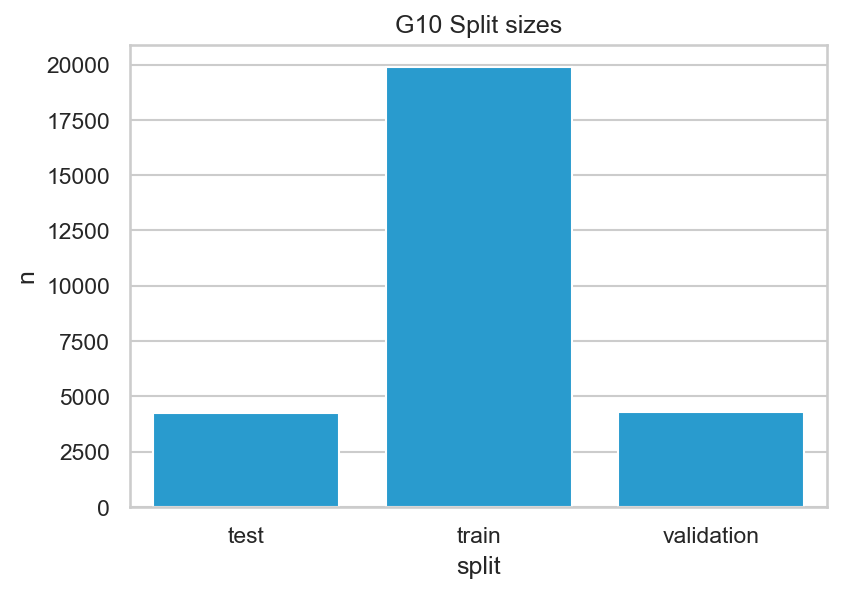

**artifacts\figures\laporan\02_label_mayoritas.png**

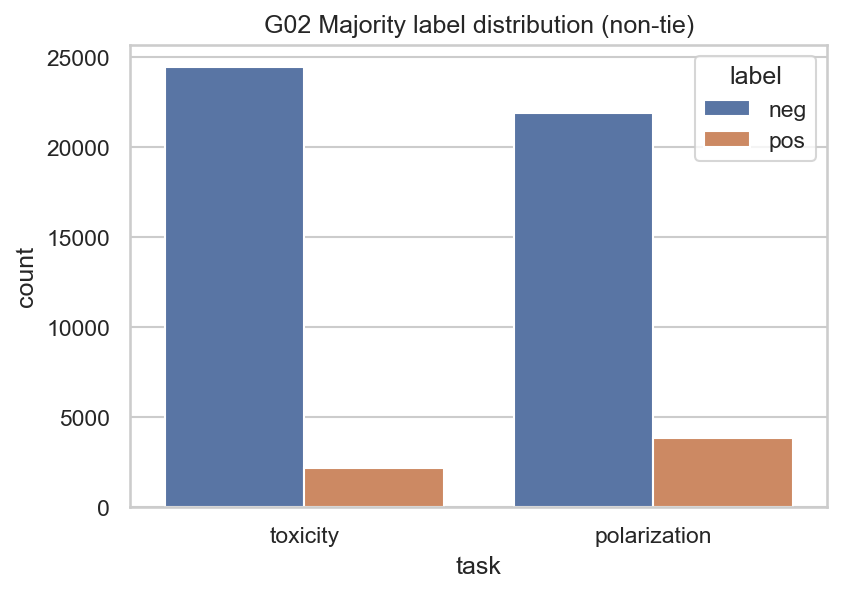

**artifacts\figures\laporan\05_distribusi_soft_toksisitas.png**

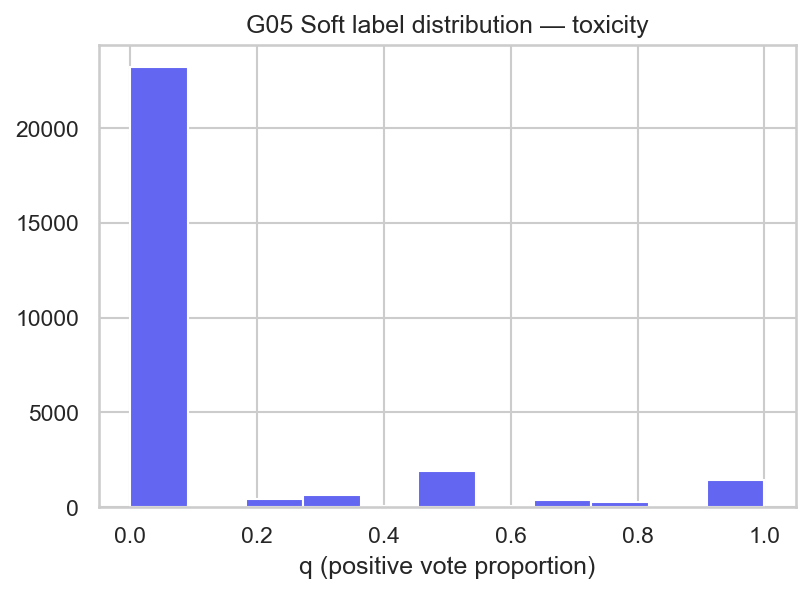

**artifacts\figures\laporan\05_distribusi_soft_polarisasi.png**

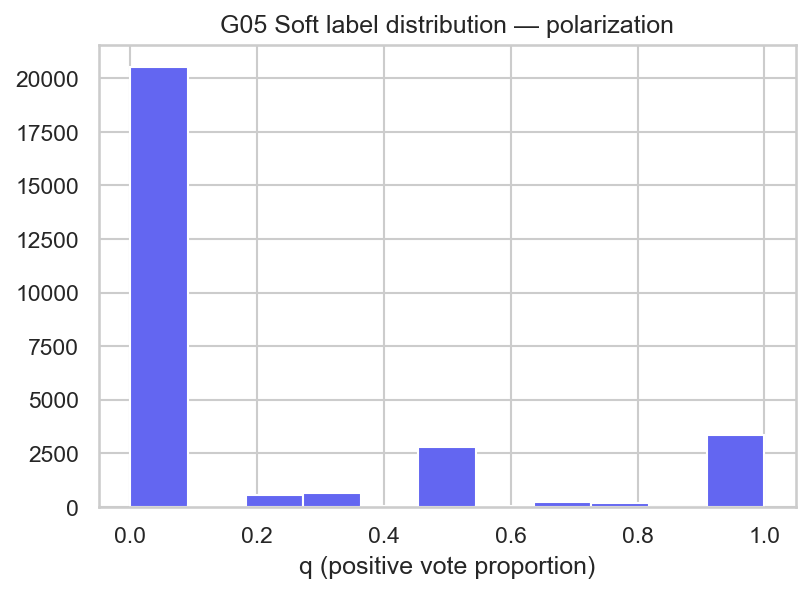

**artifacts\figures\laporan\D04_alur_statistik.png**

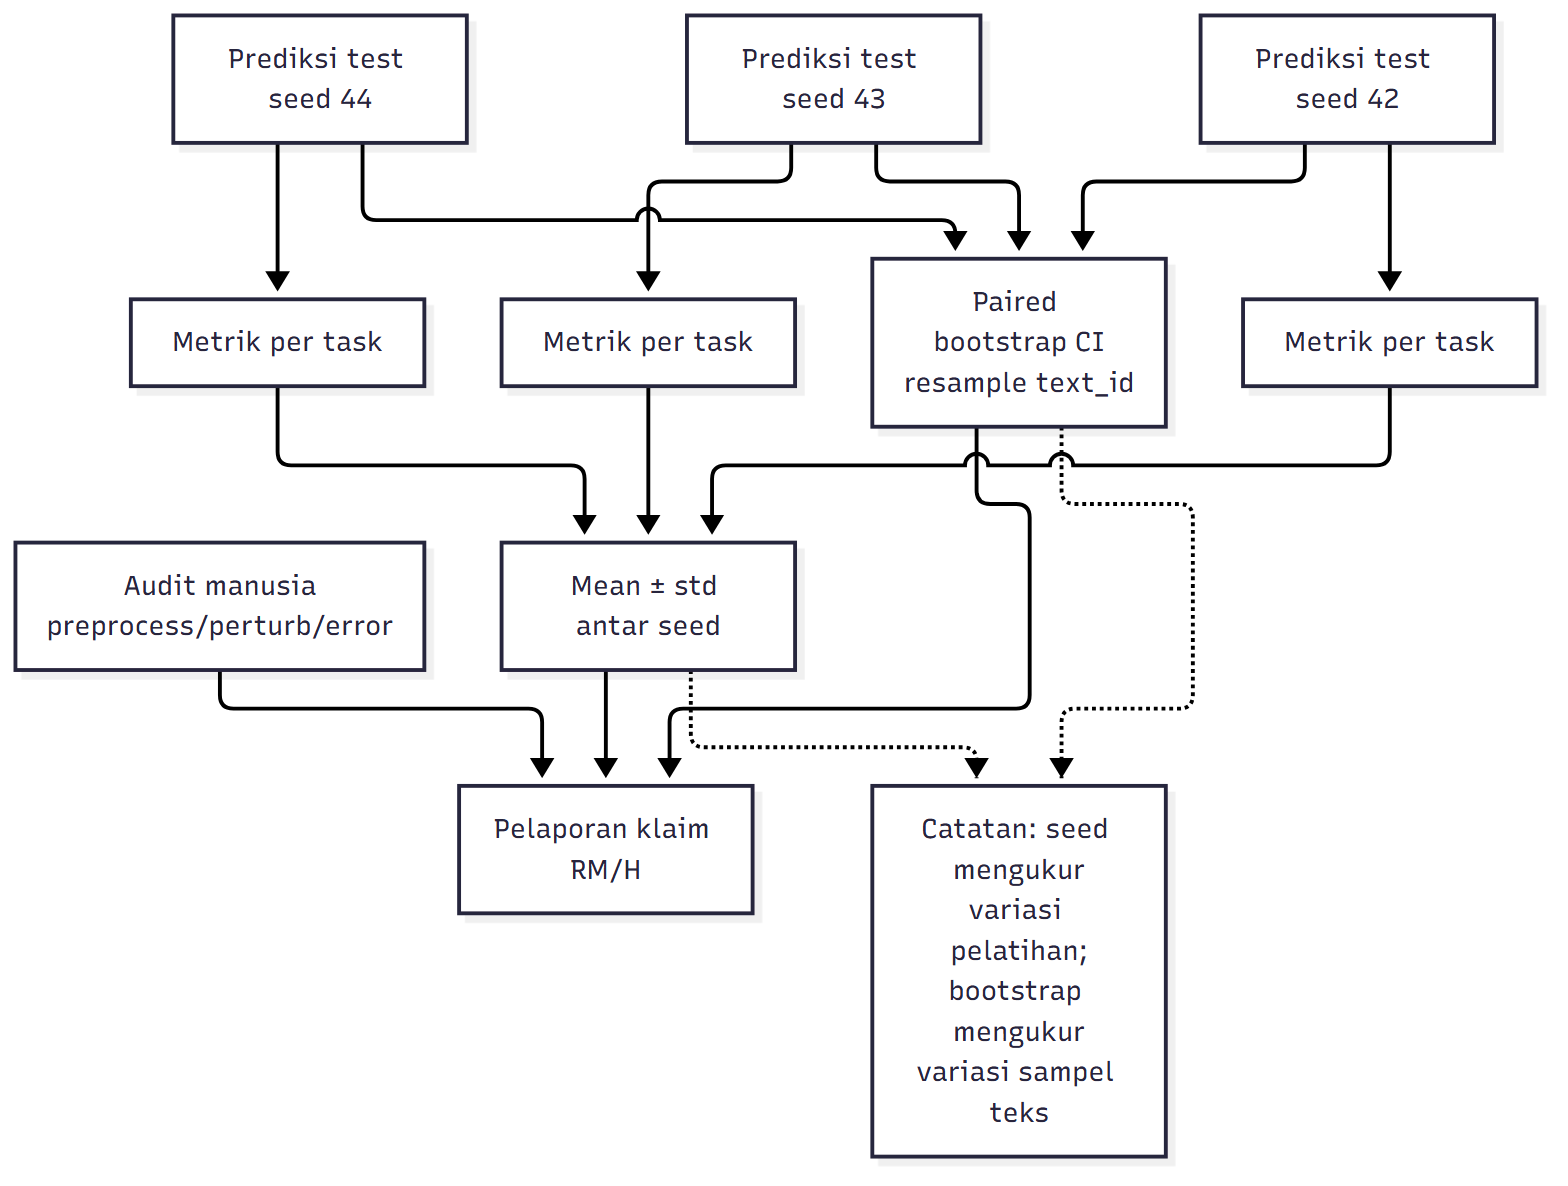

**artifacts\figures\laporan\10_perbandingan_macroF1_semua_model.png**

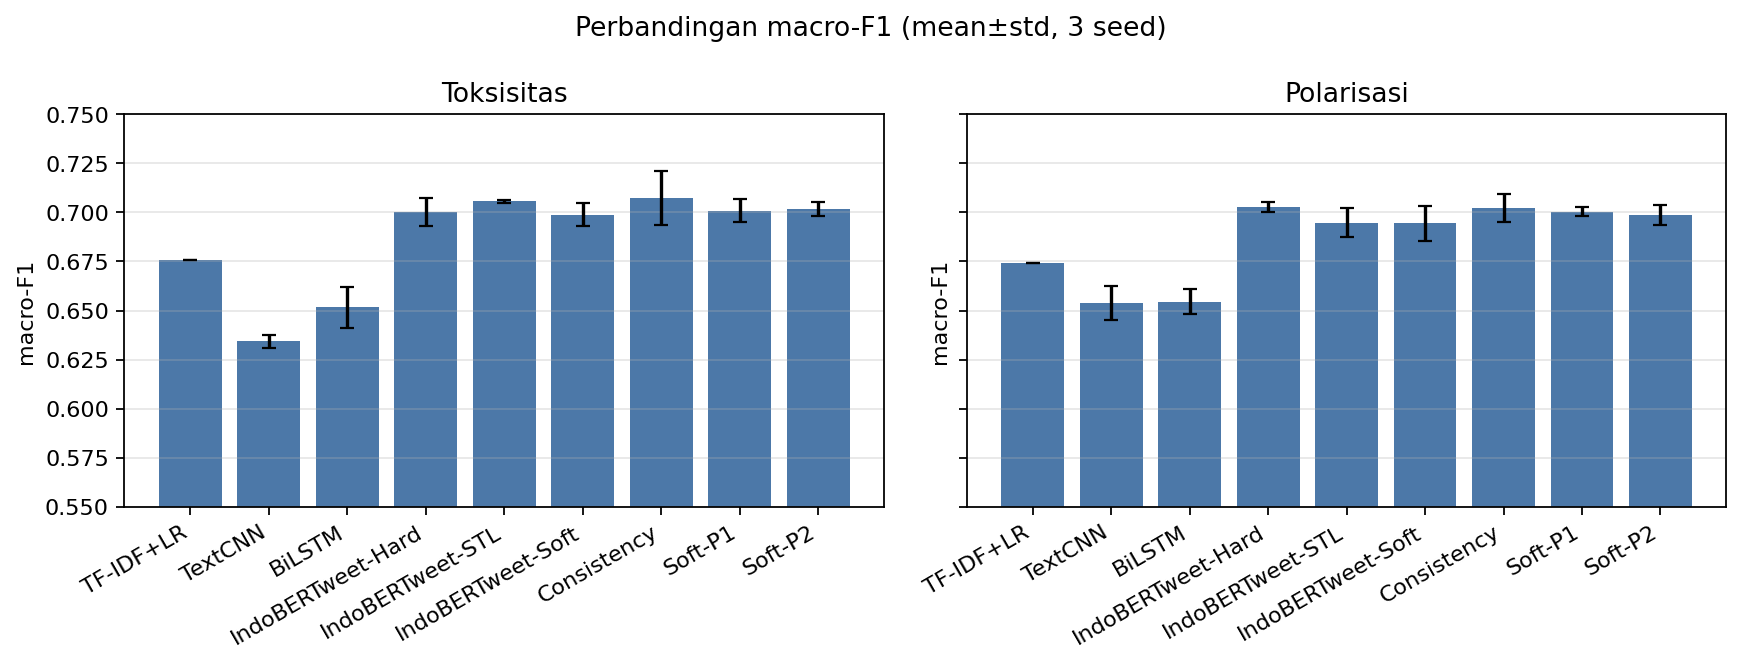

**artifacts\figures\laporan\TextCNN_toksisitas_confusion.png**

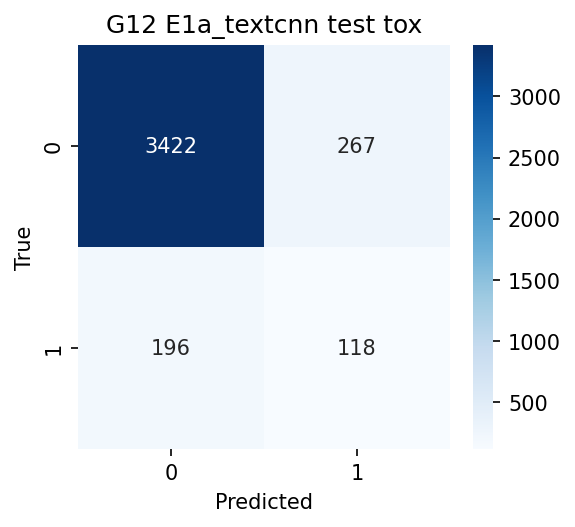

**artifacts\figures\laporan\IndoBERTweet-Hard_toksisitas_confusion.png**

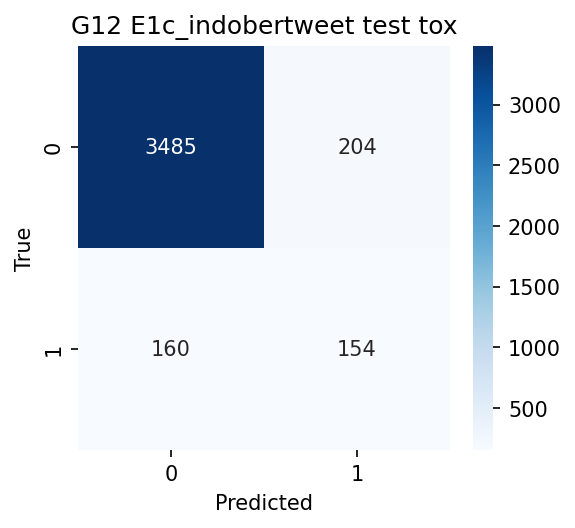

**artifacts\figures\laporan\IndoBERTweet-Hard_toksisitas_kalibrasi.png**

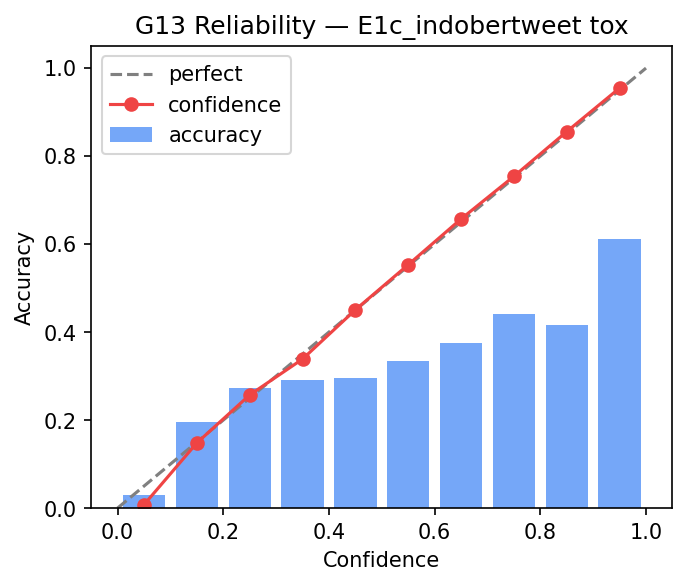

**artifacts\figures\laporan\IndoBERTweet-Soft_toksisitas_kalibrasi.png**

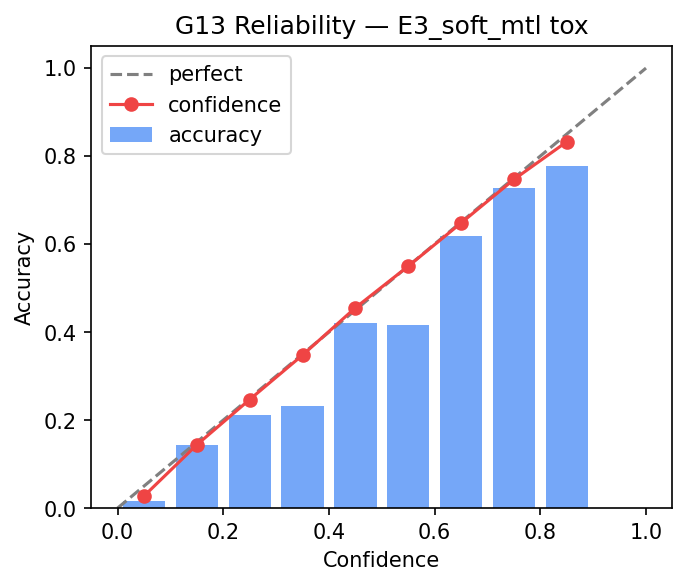

**artifacts\figures\laporan\11_robustness_delta_F1.png**

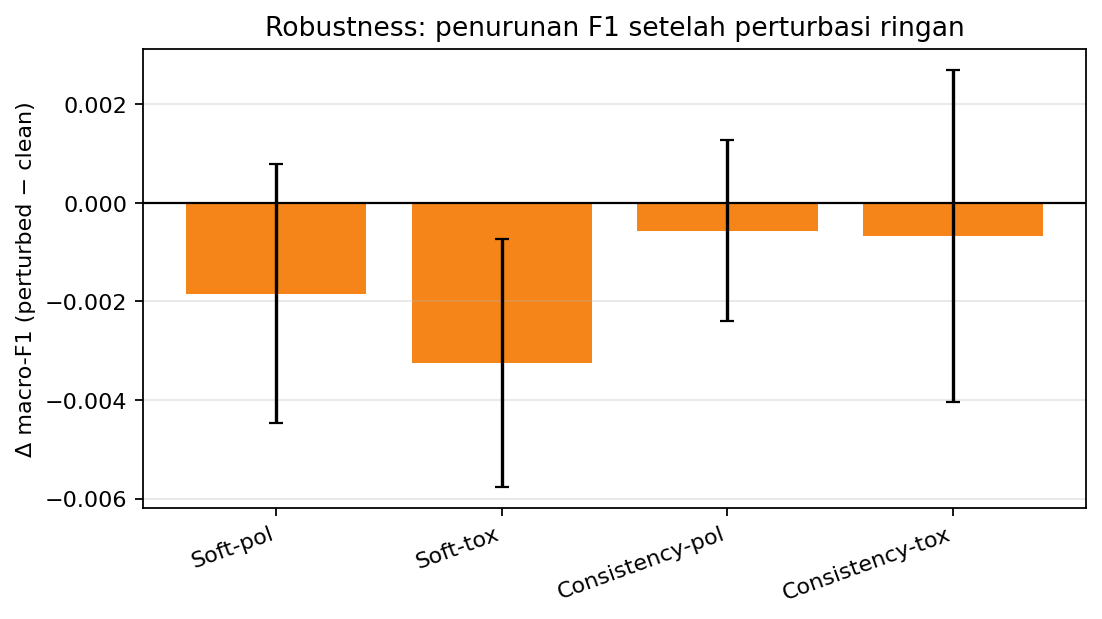

**artifacts\figures\laporan\IndoBERTweet-Soft_toksisitas_precision-recall.png**

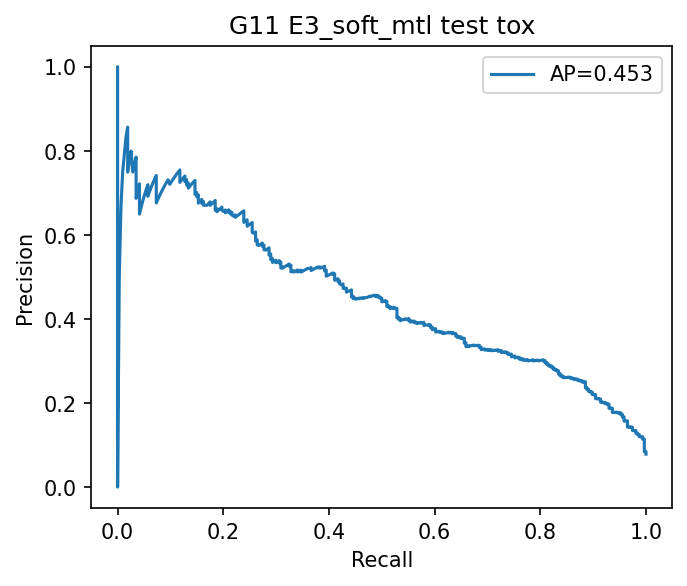

In [12]:
# Figur hasil utama (tanpa D01/D02/D03).
RESULT_FIGS = [
    "09_ukuran_split.png",
    "02_label_mayoritas.png",
    "05_distribusi_soft_toksisitas.png",
    "05_distribusi_soft_polarisasi.png",
    "D04_alur_statistik.png",
    "10_perbandingan_macroF1_semua_model.png",
    "TextCNN_toksisitas_confusion.png",
    "IndoBERTweet-Hard_toksisitas_confusion.png",
    "IndoBERTweet-Hard_toksisitas_kalibrasi.png",
    "IndoBERTweet-Soft_toksisitas_kalibrasi.png",
    "11_robustness_delta_F1.png",
    "IndoBERTweet-Soft_toksisitas_precision-recall.png",
]
EXCLUDE_FIGS = {
    "D01_tahapan_penelitian.png",   # opsional
    "D02_protokol_eksperimen.png",  # opsional
    "D03_pohon_ablasi_model.png",   # opsional
}

show_flag = globals().get("SHOW_RESULT_FIGS", globals().get("SHOW_ALL_RESULT_FIGS", True))
if show_flag:
    lap = ROOT / "artifacts" / "figures" / "laporan"
    files = [lap / name for name in RESULT_FIGS if name not in EXCLUDE_FIGS]
    print("Jumlah figur hasil (tanpa D01/D02/D03):", len(files))
    for p in files:
        show_png(p, max_width=820)
else:
    print("Skip galeri hasil")


Figur per seed

Default dimatikan. Aktifkan `SHOW_ALL_SEED_FIGS=True` hanya bila perlu inspeksi lengkap.


In [13]:
if SHOW_ALL_SEED_FIGS:
    by_dir = ROOT / "artifacts" / "figures" / "laporan" / "by_seed"
    catalog = by_dir / "daftar_gambar_by_seed.csv"
    if catalog.exists():
        cat = pd.read_csv(catalog)
        # Filter seed yang diminta; tampilkan terurut model-task-kind-seed.
        cat = cat[cat["seed"].isin(SEEDS)].copy()
        cat = cat.sort_values(["experiment_id", "task", "kind", "seed"])
        print("Jumlah figur by_seed:", len(cat))
        display(cat.groupby(["experiment_id", "seed"]).size().rename("n_figs").reset_index())
        for _, row in cat.iterrows():
            rel = row["nama_laporan"]
            path = lap_path = ROOT / "artifacts" / "figures" / "laporan" / rel
            show_png(path, max_width=760)
    else:
        # Fallback: tampilkan langsung folder seeded.
        seeded = ROOT / "artifacts" / "figures" / "seeded"
        files = sorted(seeded.glob("*_seed*/*.png"))
        print("Fallback seeded png:", len(files))
        for p in files:
            if any(f"_seed{s}" in p.as_posix() for s in SEEDS):
                show_png(p, max_width=760)
else:
    print("Skip galeri by_seed")

Skip galeri by_seed


Penutup

Pipeline menampilkan:
- prepare & EDA,
- training/evaluasi (opsional),
- agregasi metrik,
- visualisasi confusion / precision-recall / kalibrasi / banding.

Mode cepat setelah clone: biarkan `RUN_CORE_MULTISEED=False` dan `RUN_REMAINING=False`, lalu **Run All** untuk menampilkan tabel & figur dari artefak.
